⏳ Loading Keras Architecture Graph...
✅ Segmentation-only sub-model ready.

🎬 Processing Specimen 1...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


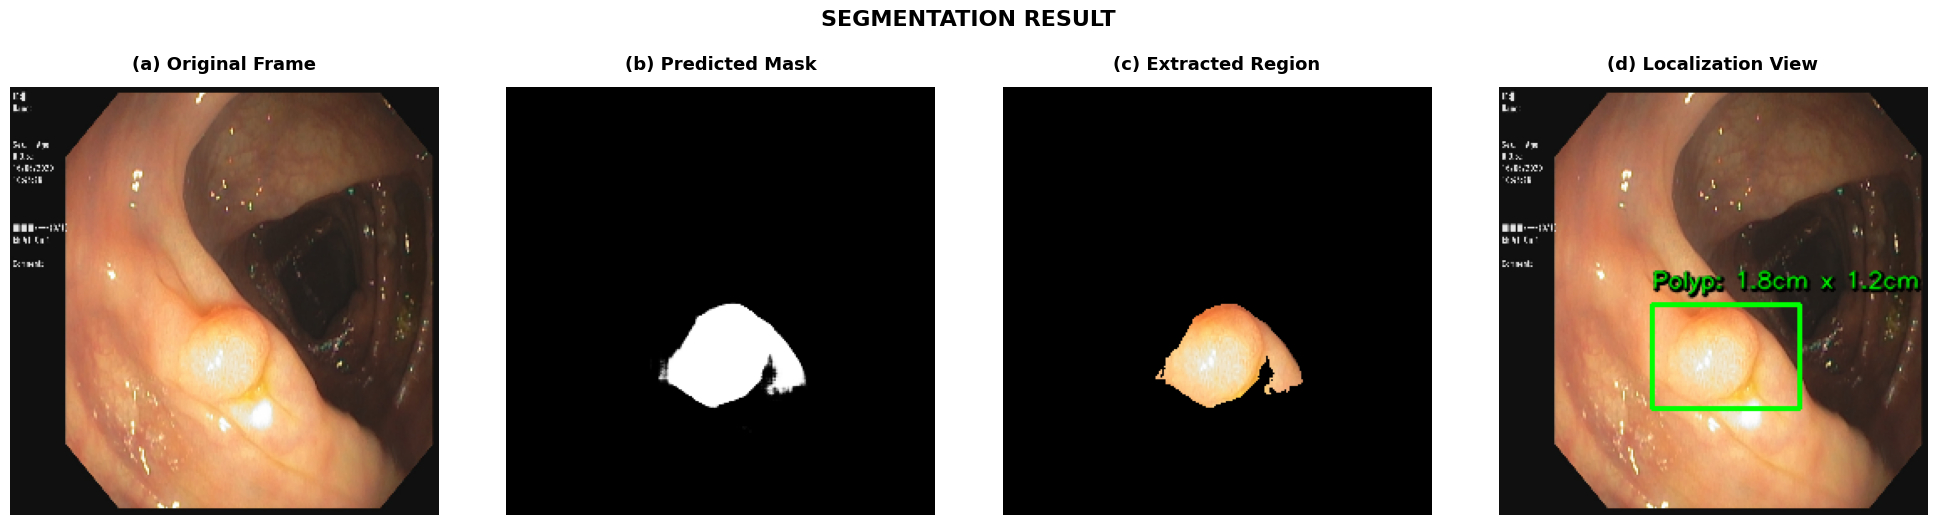

🧬 [GP SUCCESS] Genetic mask comparison saved to: thesis_positive_result_genetic.png
   • Fidelity-Focused     fitness=0.901  program=gaussian5(median3(median3(gaussian5(dilate5(erode5(mask))))))
   • Smoothness-Focused   fitness=0.775  program=median5(dilate5(open3(open3(mask))))
   • Balanced             fitness=0.788  program=open3(median3(median5(dilate5(open3(mask)))))
   • Compact-Region       fitness=0.639  program=close5(median5(close3(open5(dilate3(mask)))))


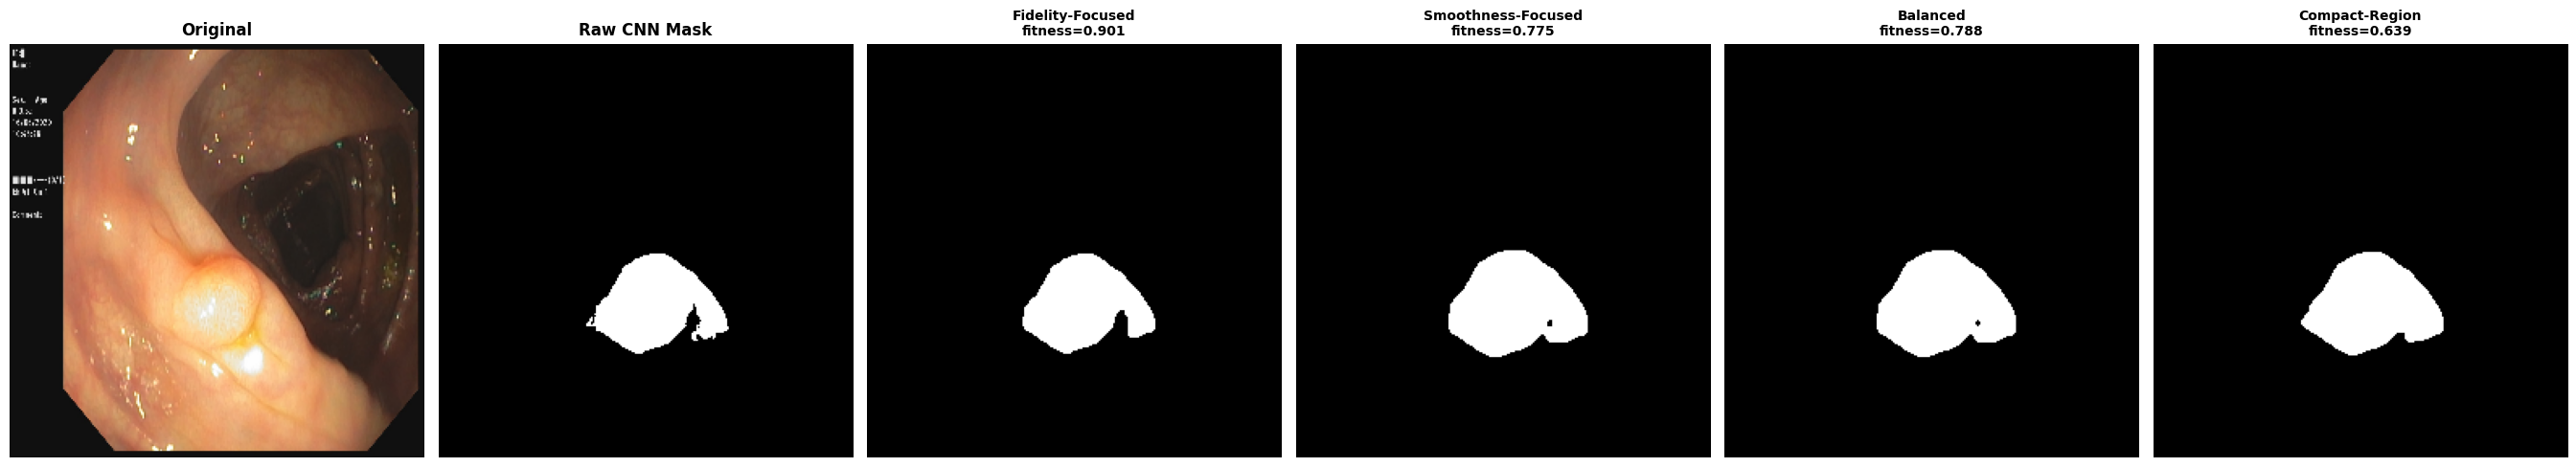


🎬 Processing Specimen 2...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: thesis_negative_result.png


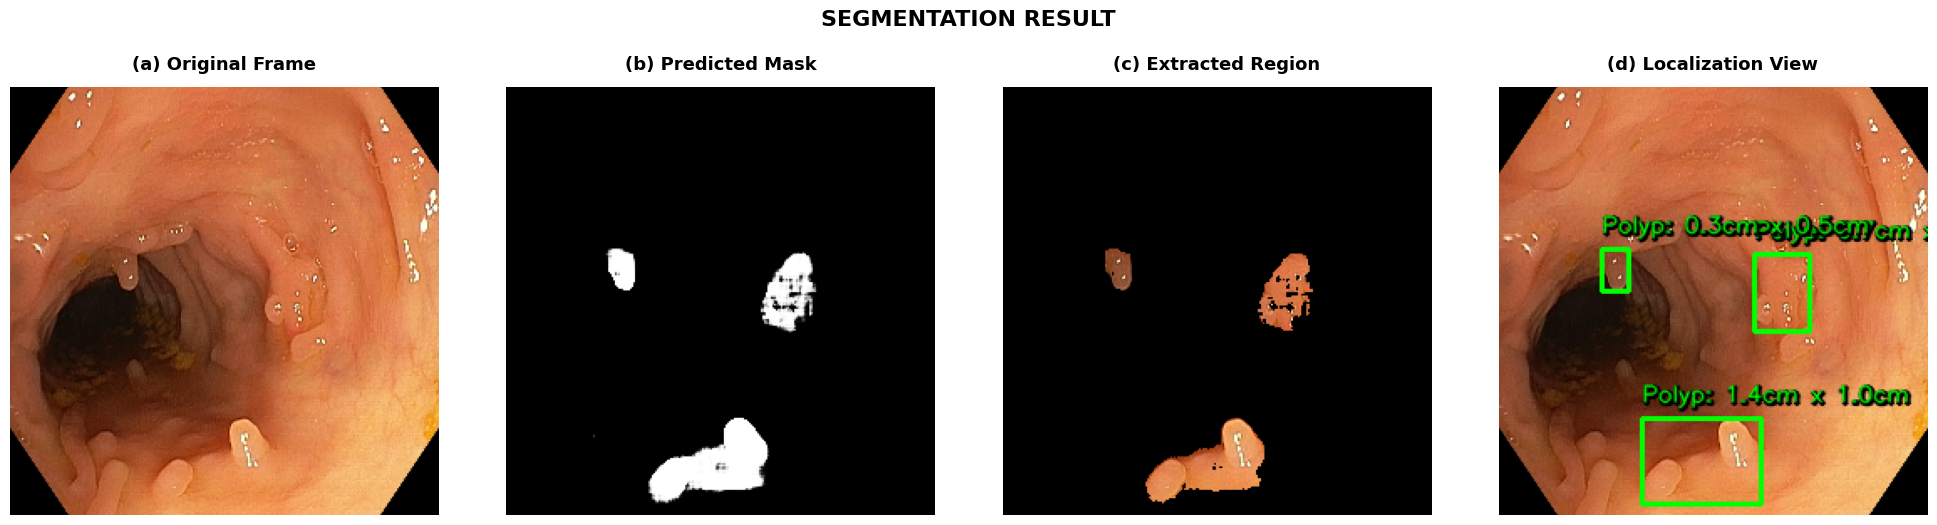

🧬 [GP SUCCESS] Genetic mask comparison saved to: thesis_negative_result_genetic.png
   • Fidelity-Focused     fitness=0.812  program=gaussian5(gaussian3(open3(mask)))
   • Smoothness-Focused   fitness=0.574  program=dilate5(median3(keep_largest(dilate3(mask))))
   • Balanced             fitness=0.642  program=close3(median3(mask))
   • Compact-Region       fitness=0.455  program=keep_largest(close5(close3(gaussian5(mask))))


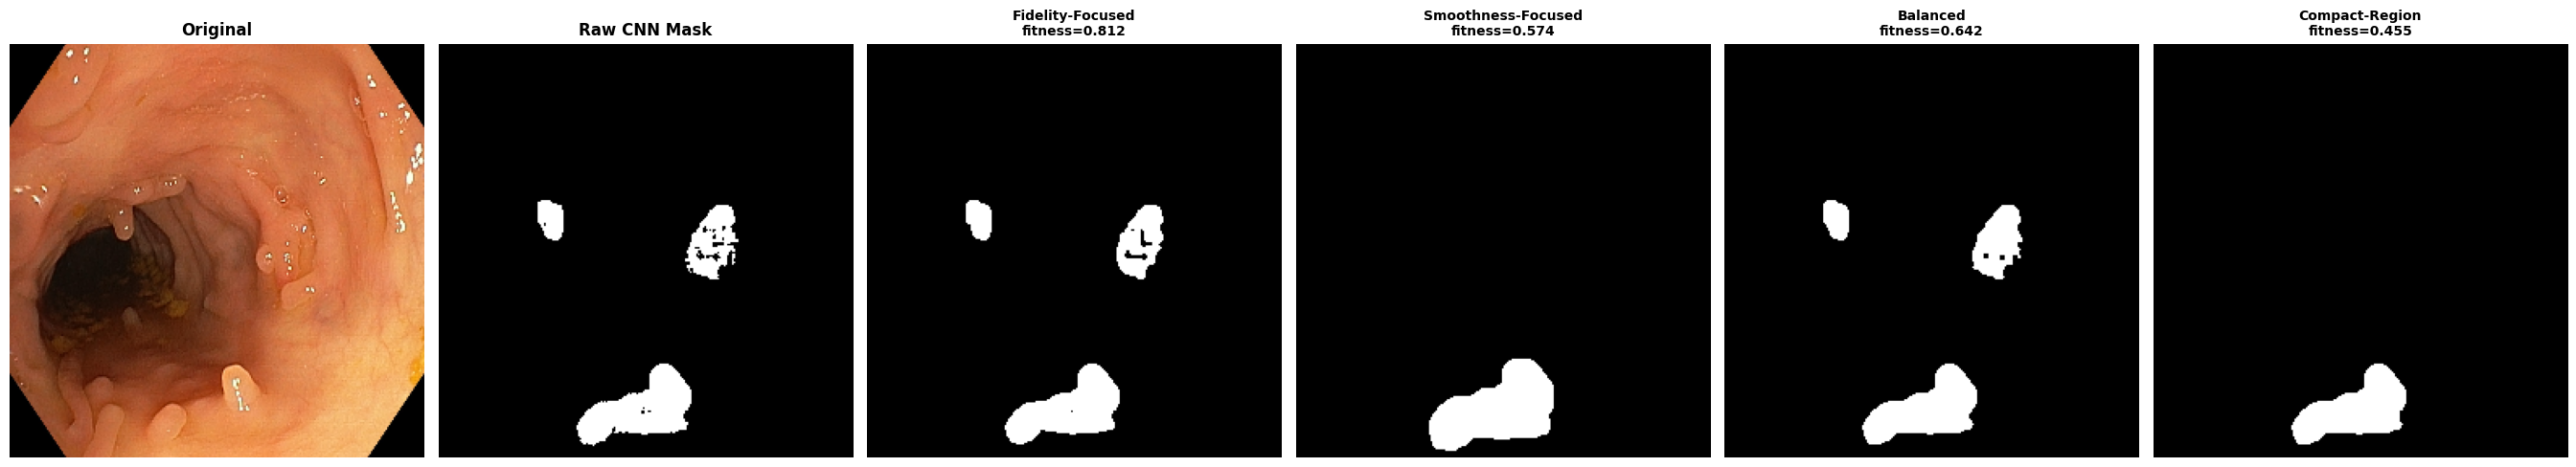


🎬 Processing Specimen 3...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg3.png


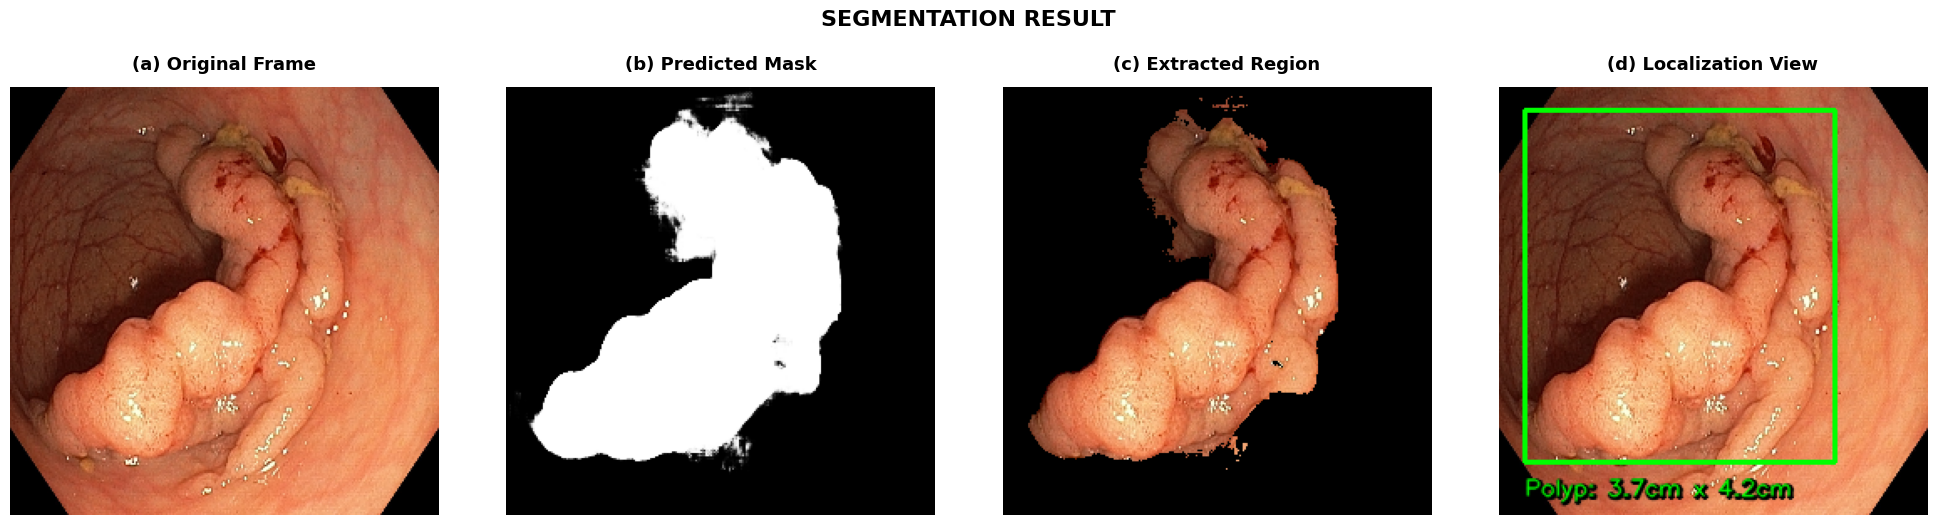

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg3_genetic.png
   • Fidelity-Focused     fitness=0.880  program=close5(fill_holes(open3(median5(open3(gaussian5(mask))))))
   • Smoothness-Focused   fitness=0.621  program=median5(open5(median3(open5(mask))))
   • Balanced             fitness=0.725  program=dilate3(open5(erode3(median5(median5(mask)))))
   • Compact-Region       fitness=0.583  program=gaussian3(open5(median5(median5(median5(open5(mask))))))


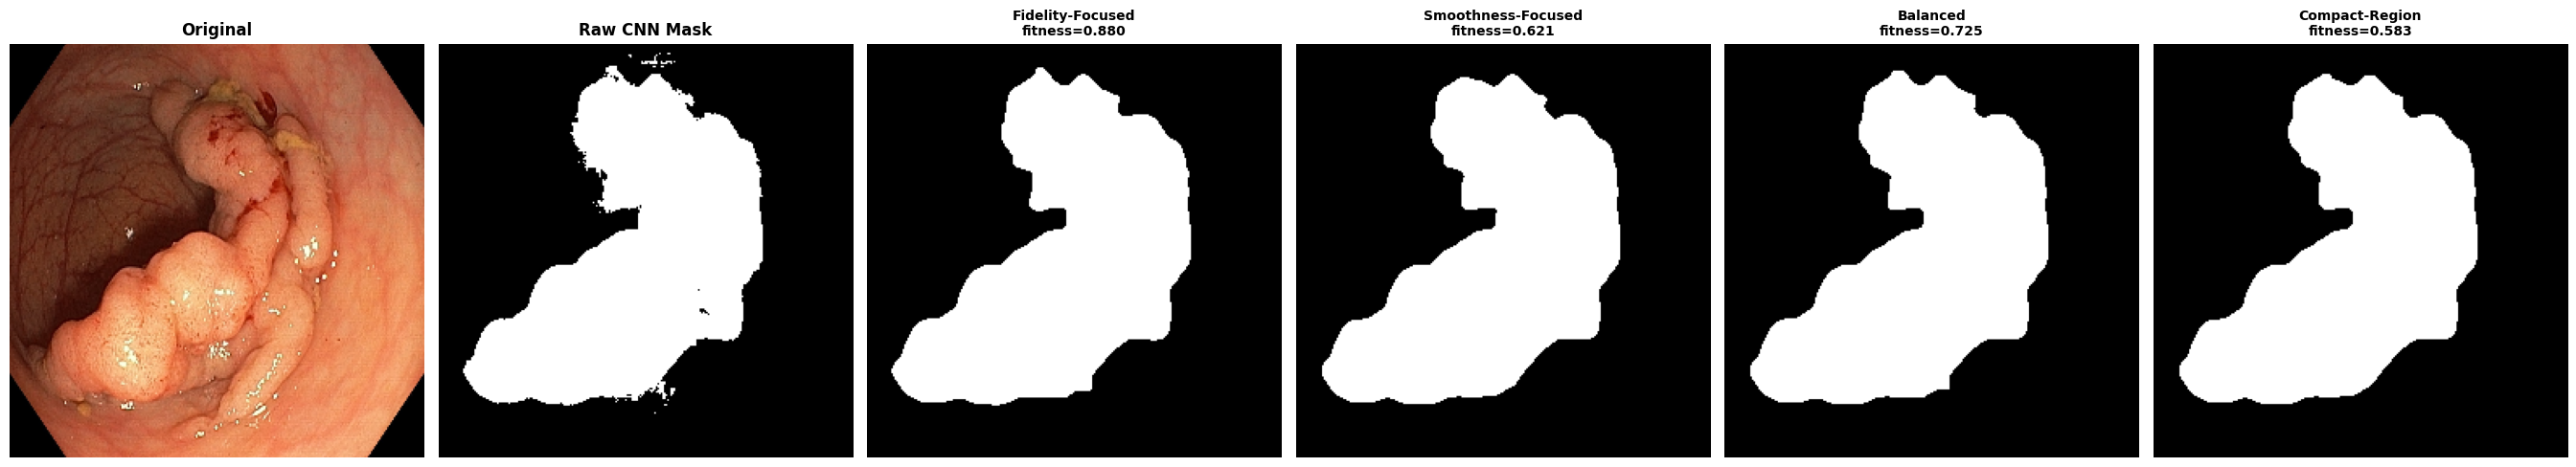


🎬 Processing Specimen 4...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg4.png


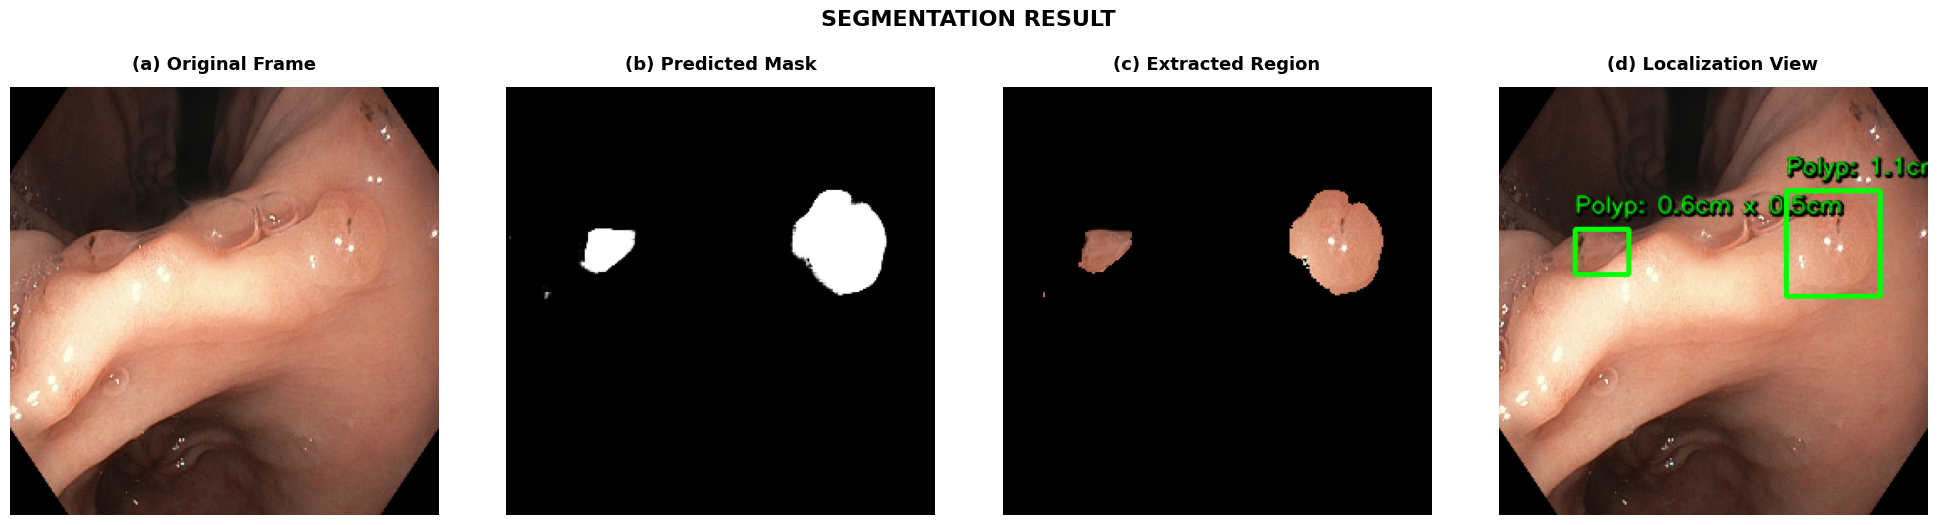

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg4_genetic.png
   • Fidelity-Focused     fitness=0.927  program=gaussian5(median3(median3(close5(close5(mask)))))
   • Smoothness-Focused   fitness=0.831  program=median5(open3(gaussian3(median5(median3(mask)))))
   • Balanced             fitness=0.868  program=close5(median5(median5(median5(close5(mask)))))
   • Compact-Region       fitness=0.642  program=median3(close3(keep_largest(mask)))


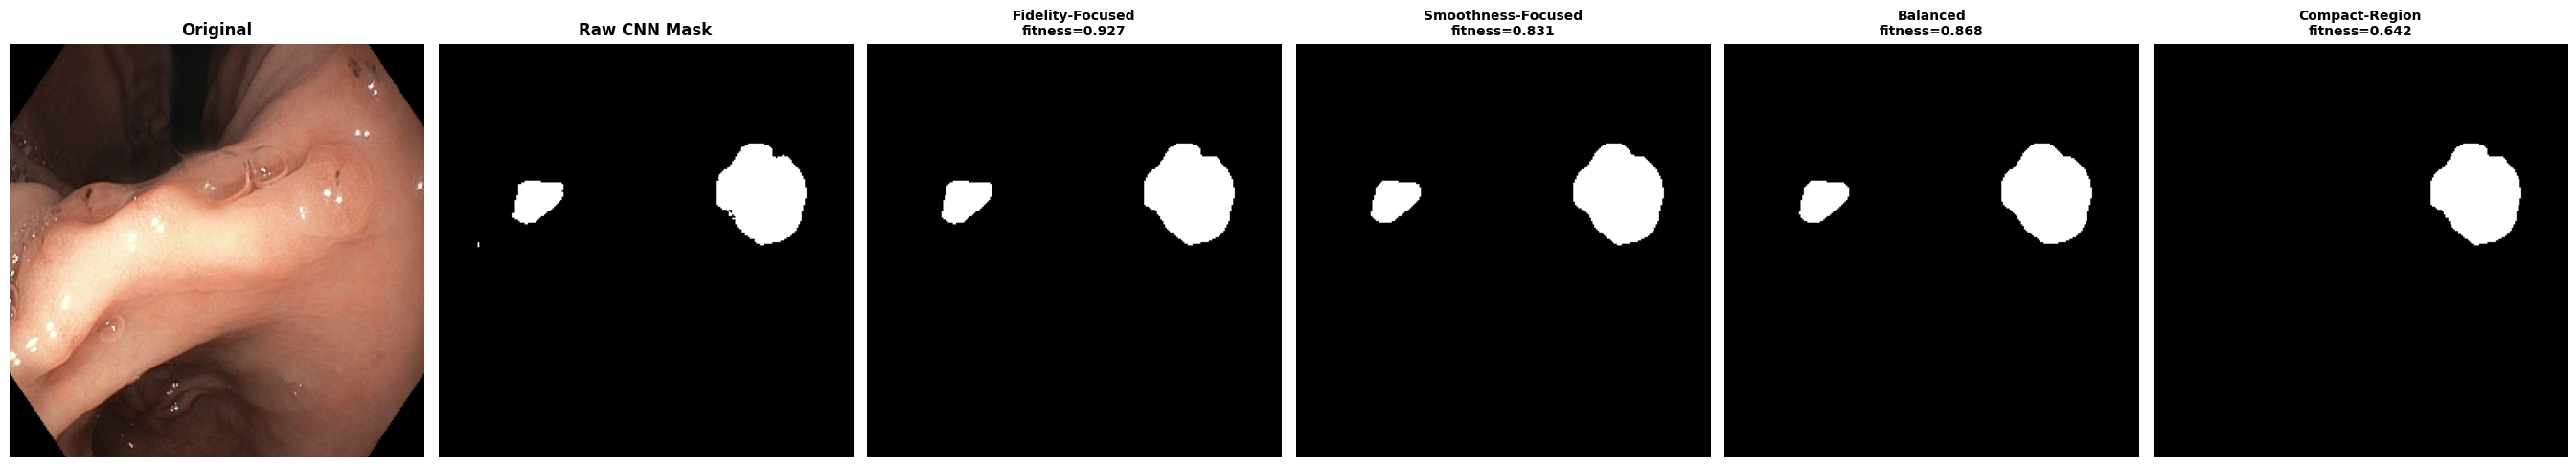


🎬 Processing Specimen 5...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg5.png


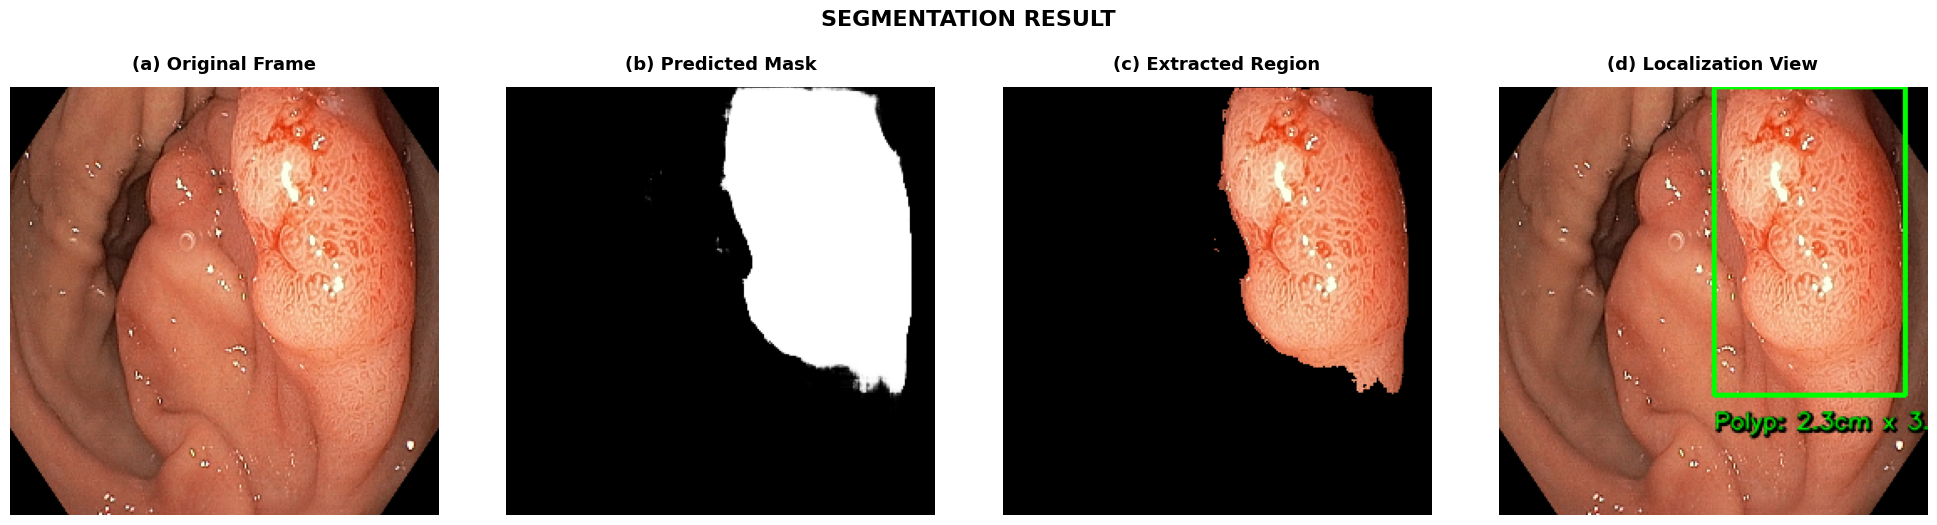

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg5_genetic.png
   • Fidelity-Focused     fitness=0.934  program=median3(median5(median5(median5(median5(open3(mask))))))
   • Smoothness-Focused   fitness=0.787  program=median5(open5(open3(mask)))
   • Balanced             fitness=0.846  program=open3(median5(median5(keep_largest(open5(mask)))))
   • Compact-Region       fitness=0.676  program=median3(open3(median5(open5(mask))))


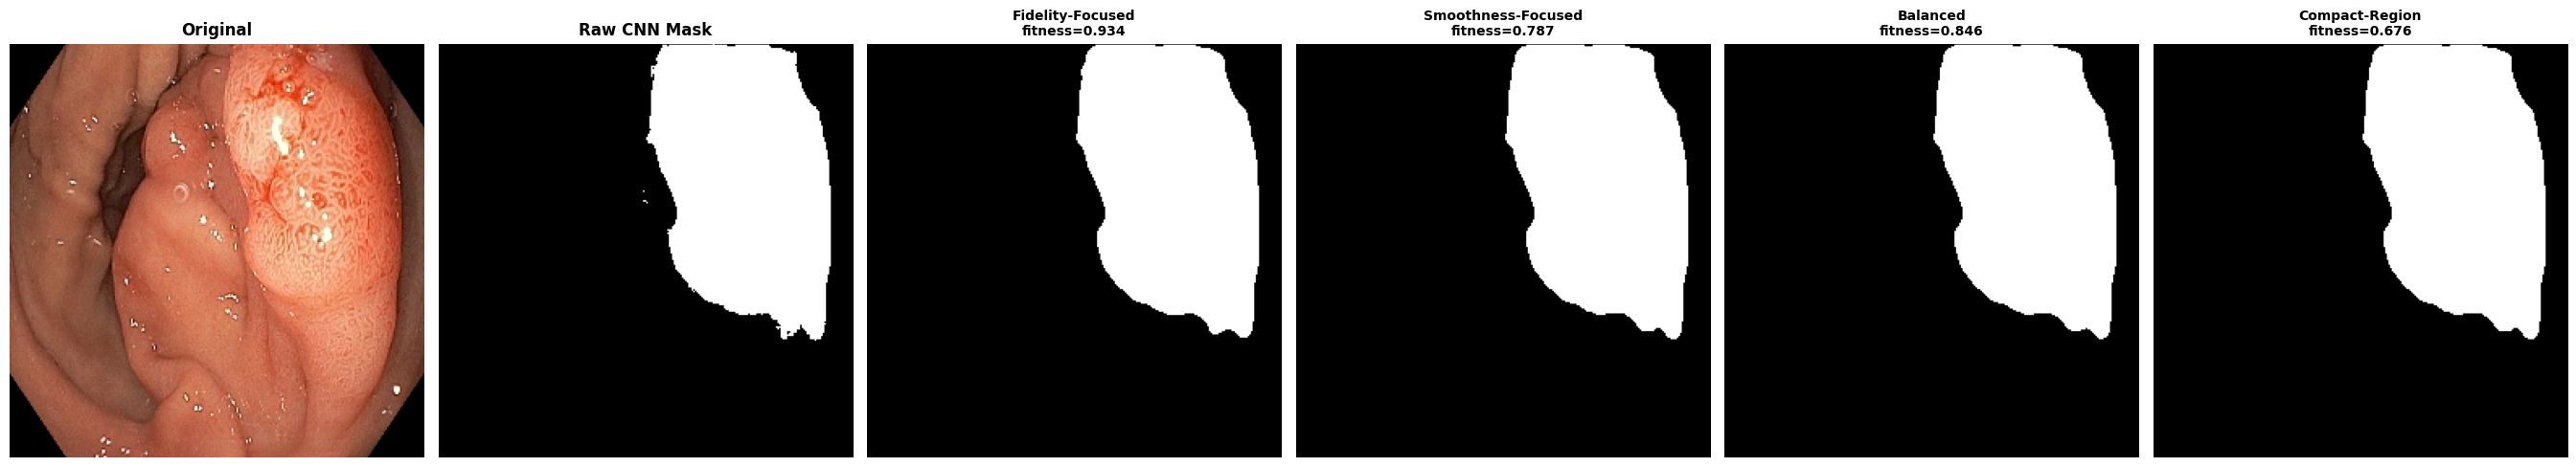

In [16]:
%matplotlib inline

import os
import cv2
import gc
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from deap import base, creator, tools, gp, algorithms

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ CONFIG
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

TEST_IMAGES = [
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0084.jpg",
"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/155OLCV1_100H0010.jpg",
"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/963OLCV1_100H0006.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/779OLCV1_100H0004.jpg",
 "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/375OLCV1_100H0008.jpg"

]


# ─────────────────────────────────────────────────────────────────────────────
# 🧬 CUSTOM LAYER (self-contained লোডিং এর জন্য)
# ─────────────────────────────────────────────────────────────────────────────
@keras.saving.register_keras_serializable(package="Custom")
class KerasPCCLayer(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs
        mean = tf.reduce_mean(x, axis=-1, keepdims=True)
        std = tf.math.reduce_std(x, axis=-1, keepdims=True) + 1e-7
        x_norm = (x - mean) / std
        outer = tf.matmul(tf.expand_dims(x_norm, axis=2), tf.expand_dims(x_norm, axis=1))
        batch = tf.shape(x)[0]
        c = tf.shape(x)[-1]
        return tf.reshape(outer, [batch, c * c])

    def compute_output_shape(self, input_shape):
        c = input_shape[-1]
        return (input_shape[0], c * c if c is not None else None)

    def get_config(self):
        return super().get_config()


# ─────────────────────────────────────────────────────────────────────────────
# 🎨 LOCALIZATION HELPER (শুধু সেগমেন্টেশনের ওপর ভিত্তি করে, ক্লাসিফিকেশন ছাড়াই)
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pixel_to_cm_ratio = 50
    for cnt in contours:
        if cv2.contourArea(cnt) < 10:
            continue
        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"

        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        cv2.putText(res_img, size_text, (x + 1, text_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)
        cv2.putText(res_img, size_text, (x, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

    return res_img


# ─────────────────────────────────────────────────────────────────────────────
# 🧬 GENETIC PROGRAMMING MODULE — MULTI-MASK BOUNDARY REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
# একটাই টাইপ (mask) ব্যবহার করা হয়েছে — kernel size আলাদা টাইপ না রেখে প্রতিটা
# সাইজের জন্য আলাদা fixed-arity primitive বানানো হয়েছে (erode3, erode5 ইত্যাদি)।
# এতে DEAP-এর typed-GP int-terminal ক্র্যাশ (IndexError) সম্পূর্ণ এড়ানো যায়।
# ৪টা ভিন্ন fitness-profile দিয়ে ৪টা স্বতন্ত্র GP evolution রান করে ৪টা মাস্ক
# পাশাপাশি জেনারেট করা হয়।
# ─────────────────────────────────────────────────────────────────────────────

GP_POP_SIZE = 24
GP_NGEN = 8

GP_PROFILES = [
    {"name": "Fidelity-Focused",   "w_iou": 0.80, "w_circ": 0.20, "comp_penalty": 0.03},
    {"name": "Smoothness-Focused", "w_iou": 0.30, "w_circ": 0.70, "comp_penalty": 0.05},
    {"name": "Balanced",           "w_iou": 0.50, "w_circ": 0.50, "comp_penalty": 0.05},
    {"name": "Compact-Region",     "w_iou": 0.40, "w_circ": 0.40, "comp_penalty": 0.15},
]


def _morph(mask, op, k):
    kernel = np.ones((k, k), np.uint8)
    return cv2.morphologyEx(mask, op, kernel)


def op_erode3(mask):  return cv2.erode(mask, np.ones((3, 3), np.uint8))
def op_erode5(mask):  return cv2.erode(mask, np.ones((5, 5), np.uint8))
def op_dilate3(mask): return cv2.dilate(mask, np.ones((3, 3), np.uint8))
def op_dilate5(mask): return cv2.dilate(mask, np.ones((5, 5), np.uint8))
def op_open3(mask):   return _morph(mask, cv2.MORPH_OPEN, 3)
def op_open5(mask):   return _morph(mask, cv2.MORPH_OPEN, 5)
def op_close3(mask):  return _morph(mask, cv2.MORPH_CLOSE, 3)
def op_close5(mask):  return _morph(mask, cv2.MORPH_CLOSE, 5)
def op_median3(mask): return cv2.medianBlur(mask, 3)
def op_median5(mask): return cv2.medianBlur(mask, 5)

def op_gaussian3(mask):
    blurred = cv2.GaussianBlur(mask, (3, 3), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_gaussian5(mask):
    blurred = cv2.GaussianBlur(mask, (5, 5), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_keep_largest(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return mask
    out = np.zeros_like(mask)
    largest = max(contours, key=cv2.contourArea)
    cv2.drawContours(out, [largest], -1, 255, thickness=cv2.FILLED)
    return out

def op_fill_holes(mask):
    h, w = mask.shape
    flood = mask.copy()
    ff_mask = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(flood, ff_mask, (0, 0), 255)
    flood_inv = cv2.bitwise_not(flood)
    return mask | flood_inv


# ── Single-type (untyped) GP primitive set: mask -> mask ──
pset = gp.PrimitiveSet("MASK_GP", 1)
pset.renameArguments(ARG0="mask")

_PRIMITIVES = [
    (op_erode3, "erode3"), (op_erode5, "erode5"),
    (op_dilate3, "dilate3"), (op_dilate5, "dilate5"),
    (op_open3, "open3"), (op_open5, "open5"),
    (op_close3, "close3"), (op_close5, "close5"),
    (op_median3, "median3"), (op_median5, "median5"),
    (op_gaussian3, "gaussian3"), (op_gaussian5, "gaussian5"),
    (op_keep_largest, "keep_largest"), (op_fill_holes, "fill_holes"),
]
for _func, _name in _PRIMITIVES:
    pset.addPrimitive(_func, 1, name=_name)

if not hasattr(creator, "GPFitnessMax"):
    creator.create("GPFitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "GPIndividual"):
    creator.create("GPIndividual", gp.PrimitiveTree, fitness=creator.GPFitnessMax)


def eval_mask_program(individual, raw_mask_uint8, profile, compiler):
    func = compiler(expr=individual)
    try:
        candidate = func(raw_mask_uint8.copy())
    except Exception:
        return (-1.0,)

    if candidate is None or not isinstance(candidate, np.ndarray):
        return (-1.0,)
    candidate = (candidate > 127).astype(np.uint8) * 255
    if candidate.sum() == 0:
        return (-1.0,)

    inter = np.logical_and(candidate > 0, raw_mask_uint8 > 0).sum()
    union = np.logical_or(candidate > 0, raw_mask_uint8 > 0).sum()
    iou = inter / (union + 1e-7)

    contours, _ = cv2.findContours(candidate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return (-1.0,)
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    perimeter = cv2.arcLength(largest, True)
    if area <= 0 or perimeter <= 0:
        return (-1.0,)
    circularity = min((4 * np.pi * area) / (perimeter ** 2), 1.0)

    component_penalty = max(0, len(contours) - 1) * profile["comp_penalty"]

    score = (profile["w_iou"] * iou) + (profile["w_circ"] * circularity) - component_penalty
    return (score,)


def build_gp_toolbox(raw_mask_uint8, profile):
    toolbox = base.Toolbox()
    toolbox.register("expr", gp.genGrow, pset=pset, min_=1, max_=4)
    toolbox.register("individual", tools.initIterate, creator.GPIndividual, toolbox.expr)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("compile", gp.compile, pset=pset)
    toolbox.register("evaluate", eval_mask_program, raw_mask_uint8=raw_mask_uint8,
                      profile=profile, compiler=toolbox.compile)
    toolbox.register("mate", gp.cxOnePoint)
    toolbox.register("expr_mut", gp.genGrow, min_=0, max_=2)
    toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.decorate("mate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    toolbox.decorate("mutate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    return toolbox


def run_gp_evolution(raw_mask_uint8, profile, pop_size=GP_POP_SIZE, ngen=GP_NGEN, seed=None):
    if seed is not None:
        random.seed(seed)

    toolbox = build_gp_toolbox(raw_mask_uint8, profile)
    pop = toolbox.population(n=pop_size)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.6, mutpb=0.3, ngen=ngen,
                         halloffame=hof, verbose=False)

    best = hof[0]
    func = toolbox.compile(expr=best)
    refined = func(raw_mask_uint8.copy())
    refined = (refined > 127).astype(np.uint8) * 255
    return refined, str(best), best.fitness.values[0]


def generate_genetic_masks(raw_mask_uint8, pop_size=GP_POP_SIZE, ngen=GP_NGEN):
    """raw predicted mask থেকে GP_PROFILES অনুযায়ী ৪টা ভিন্ন refined mask তৈরি করে।"""
    results = []
    for i, profile in enumerate(GP_PROFILES):
        mask, program_str, score = run_gp_evolution(
            raw_mask_uint8, profile, pop_size=pop_size, ngen=ngen, seed=100 + i
        )
        results.append({
            "name": profile["name"],
            "mask": mask,
            "program": program_str,
            "fitness": score,
        })
    return results


def to_binary_uint8(prob_mask, thresh=0.5):
    m = prob_mask
    if m.ndim == 3:
        m = m[..., 0]
    return (m > thresh).astype(np.uint8) * 255


def plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, output_filename):
    n = len(genetic_results) + 2  # original + raw mask + 4 genetic masks
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img_res)
    axes[0].set_title("Original", fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(raw_mask_uint8, cmap="gray")
    axes[1].set_title("Raw CNN Mask", fontweight="bold")
    axes[1].axis("off")

    for i, res in enumerate(genetic_results):
        ax = axes[2 + i]
        ax.imshow(res["mask"], cmap="gray")
        ax.set_title(f"{res['name']}\nfitness={res['fitness']:.3f}", fontsize=10, fontweight="bold")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches="tight")
    print(f"🧬 [GP SUCCESS] Genetic mask comparison saved to: {output_filename}")
    for res in genetic_results:
        print(f"   • {res['name']:<20} fitness={res['fitness']:.3f}  program={res['program']}")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────────
# 🔮 SEGMENTATION-ONLY INFERENCE + GP MULTI-MASK REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
def preprocess(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, inp


def test_and_display(seg_model, image_path, output_filename='result.png'):
    img_res, inp = preprocess(image_path)

    pred = seg_model.predict(inp, verbose=0)
    pred_mask_spatial = pred[0]  # (H, W, 1)

    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)

    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    plt.suptitle("SEGMENTATION RESULT", fontsize=16, fontweight='bold', y=1.04)
    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()

    # ── 🧬 GP MULTI-MASK REFINEMENT (৪টা মাস্ক পাশাপাশি) ──
    raw_mask_uint8 = to_binary_uint8(pred_mask_spatial)
    genetic_results = generate_genetic_masks(raw_mask_uint8)
    gp_output_filename = output_filename.replace('.png', '_genetic.png')
    plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, gp_output_filename)

    gc.collect()


# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph...")
    full_model = tf.keras.models.load_model(
        MODEL_PATH, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # শুধু সেগমেন্টেশন আউটপুট পর্যন্ত সাব-মডেল — ক্লাসিফিকেশন হেড গ্রাফেই থাকবে না
    seg_model = tf.keras.Model(
        inputs=full_model.inputs,
        outputs=full_model.get_layer(name="seg_output").output,
        name="segmentation_only_model",
    )
    print("✅ Segmentation-only sub-model ready.\n")

    output_names = ['thesis_positive_result.png', 'thesis_negative_result.png',
                     'Neg3.png', 'Neg4.png', 'Neg5.png']

    for i, path in enumerate(TEST_IMAGES):
        print(f"🎬 Processing Specimen {i + 1}...")
        test_and_display(seg_model, path, output_names[i])
        print()

I0000 00:00:1784022251.047206   84536 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


✅ GPU Memory Growth Enabled
⏳ Loading Keras Architecture Graph...


I0000 00:00:1784022305.730975   84536 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


✅ Segmentation-only sub-model ready.

🎬 Processing Specimen 1...


I0000 00:00:1784022310.297719   86454 service.cc:153] XLA service 0x7e0f94058580 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784022310.297758   86454 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784022310.406802   86454 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784022310.996901   86454 cuda_dnn.cc:461] Loaded cuDNN version 92101
E0000 00:00:1784022315.704394   86454 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1784022316.730419   86454 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I

🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


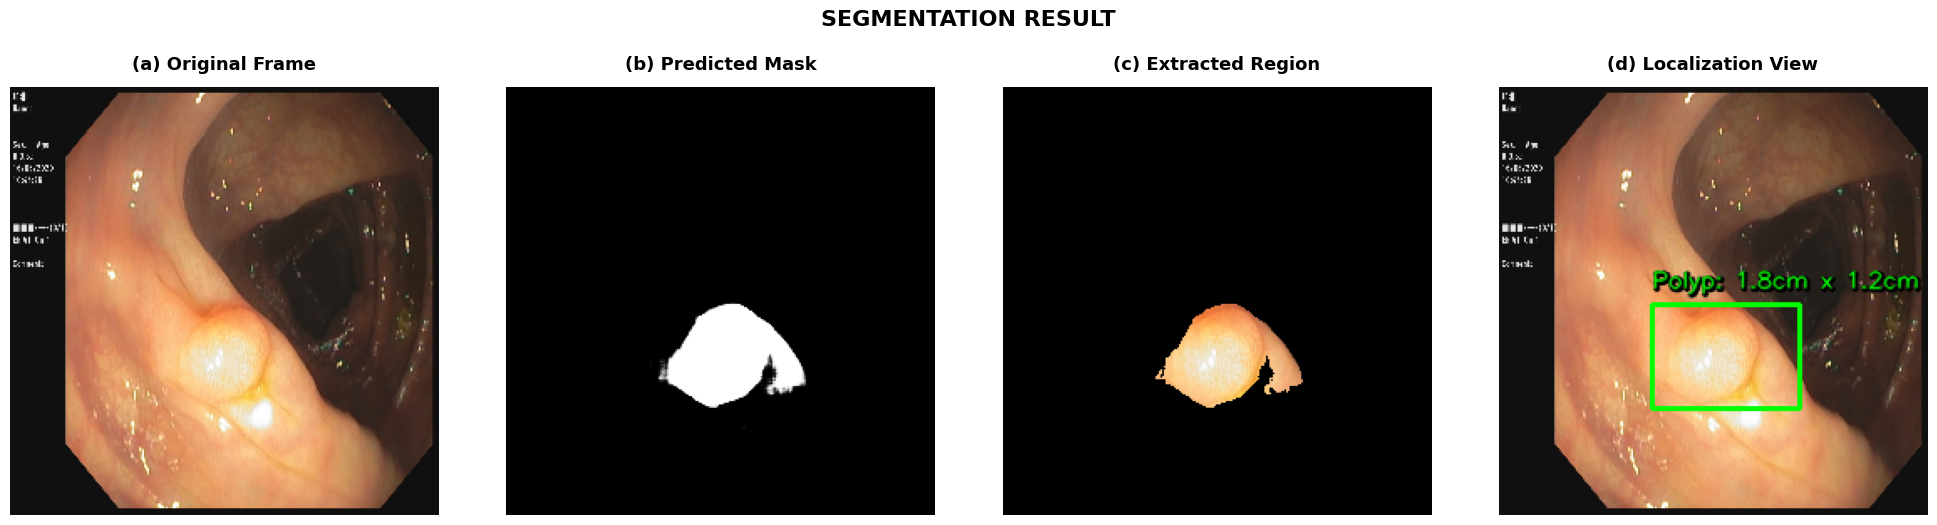

🧬 [GP SUCCESS] Genetic mask comparison saved to: thesis_positive_result_genetic.png
   • Fidelity-Focused     fitness=0.903  program=close5(close5(median3(dilate5(erode5(mask)))))
   • Smoothness-Focused   fitness=0.775  program=median5(dilate5(open3(open3(mask))))
   • Balanced             fitness=0.788  program=open3(median3(median5(dilate5(open3(mask)))))
   • Compact-Region       fitness=0.637  program=median3(close5(close5(close3(open5(dilate3(mask))))))


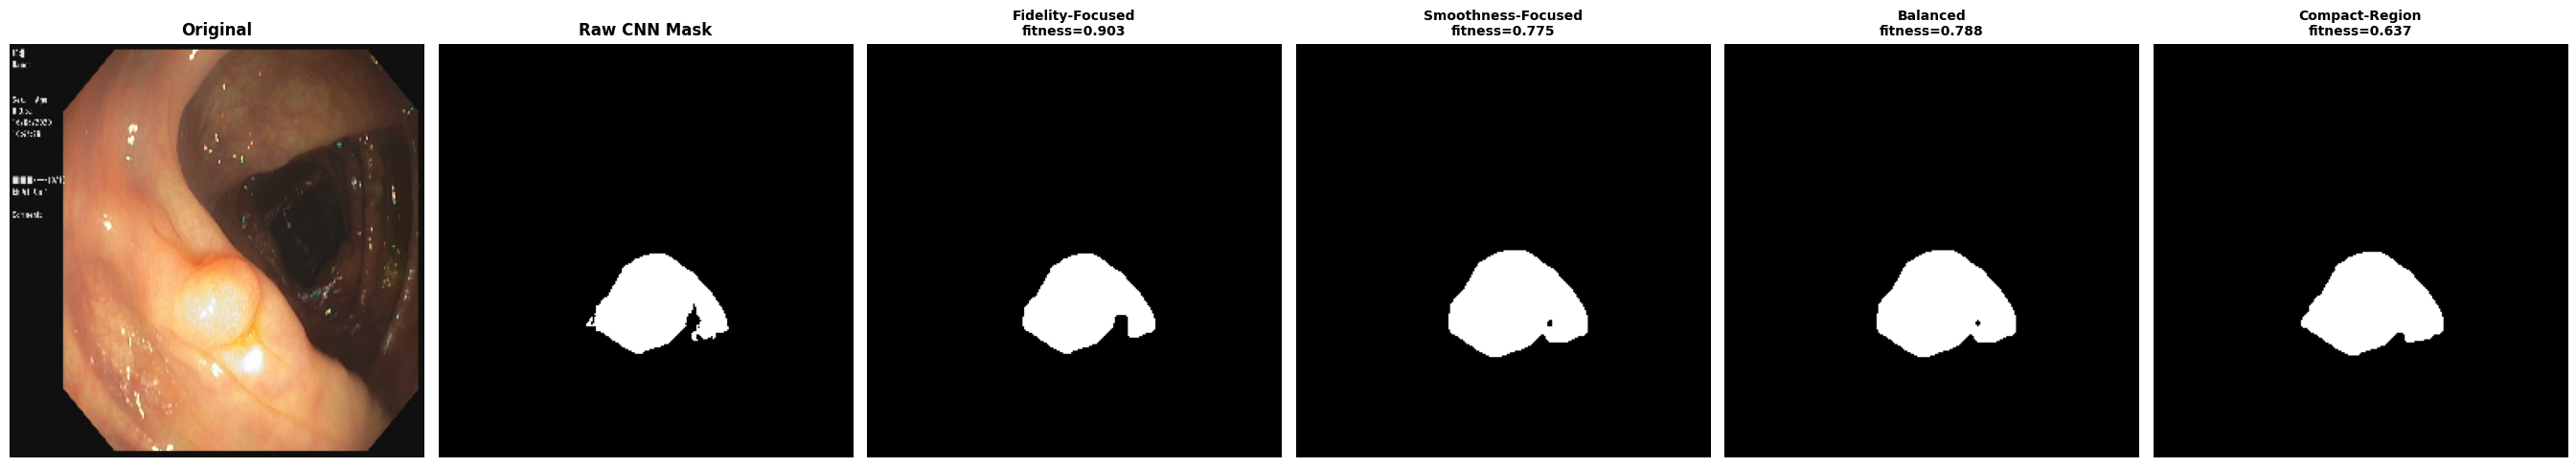


🎬 Processing Specimen 2...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: thesis_negative_result.png


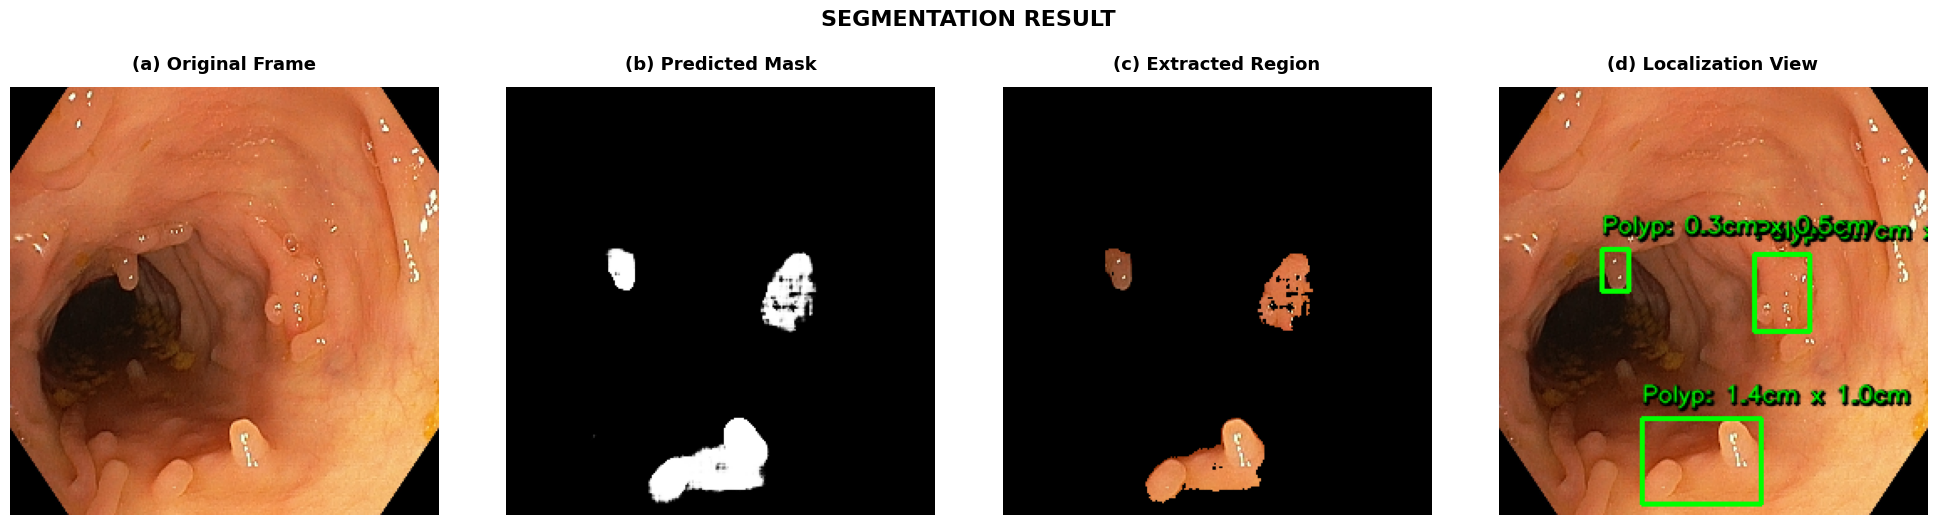

🧬 [GP SUCCESS] Genetic mask comparison saved to: thesis_negative_result_genetic.png
   • Fidelity-Focused     fitness=0.812  program=gaussian5(gaussian3(open3(mask)))
   • Smoothness-Focused   fitness=0.574  program=dilate5(median3(keep_largest(dilate3(mask))))
   • Balanced             fitness=0.642  program=close3(median3(mask))
   • Compact-Region       fitness=0.455  program=keep_largest(close5(close3(gaussian5(mask))))


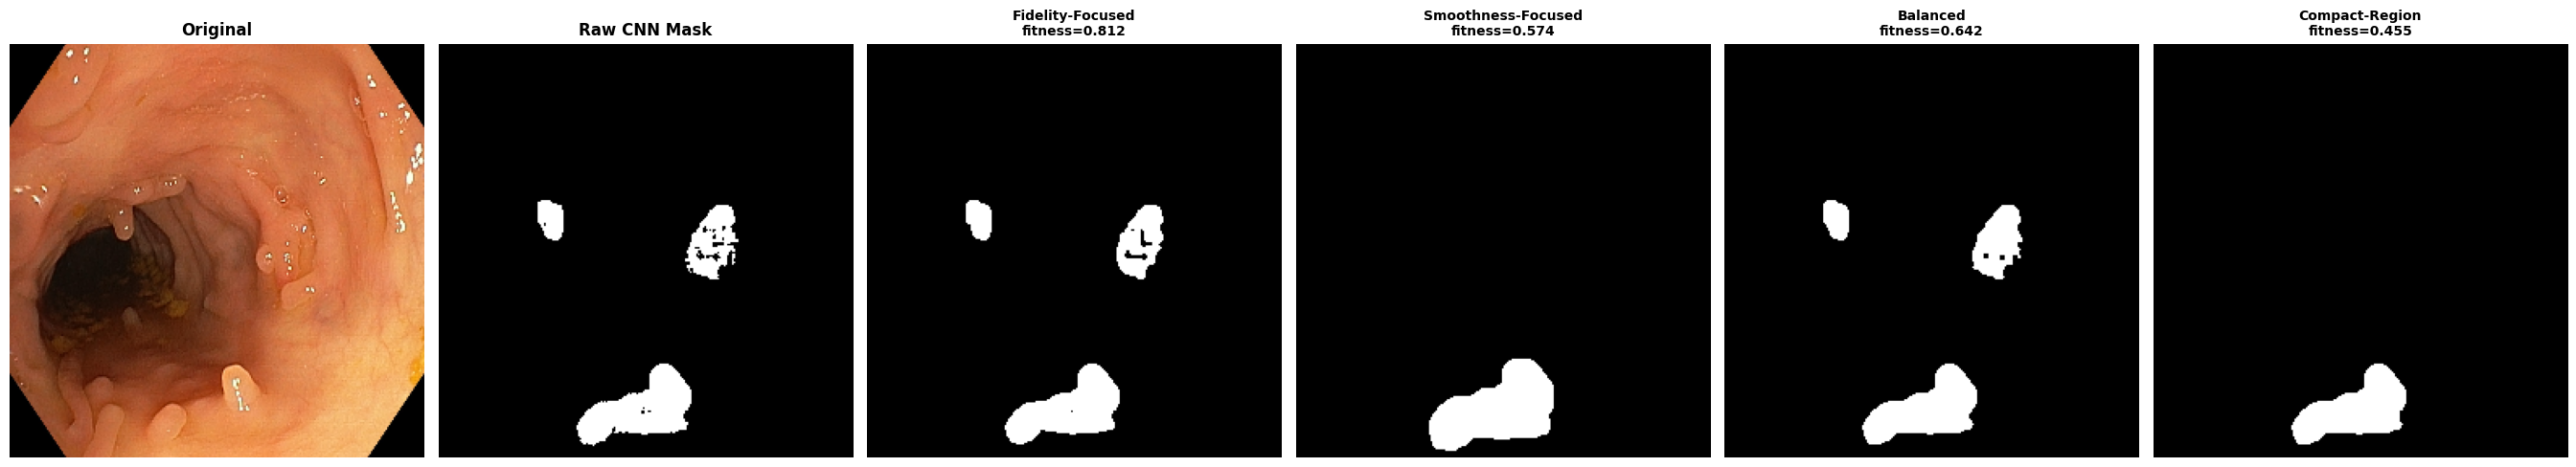


🎬 Processing Specimen 3...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg3.png


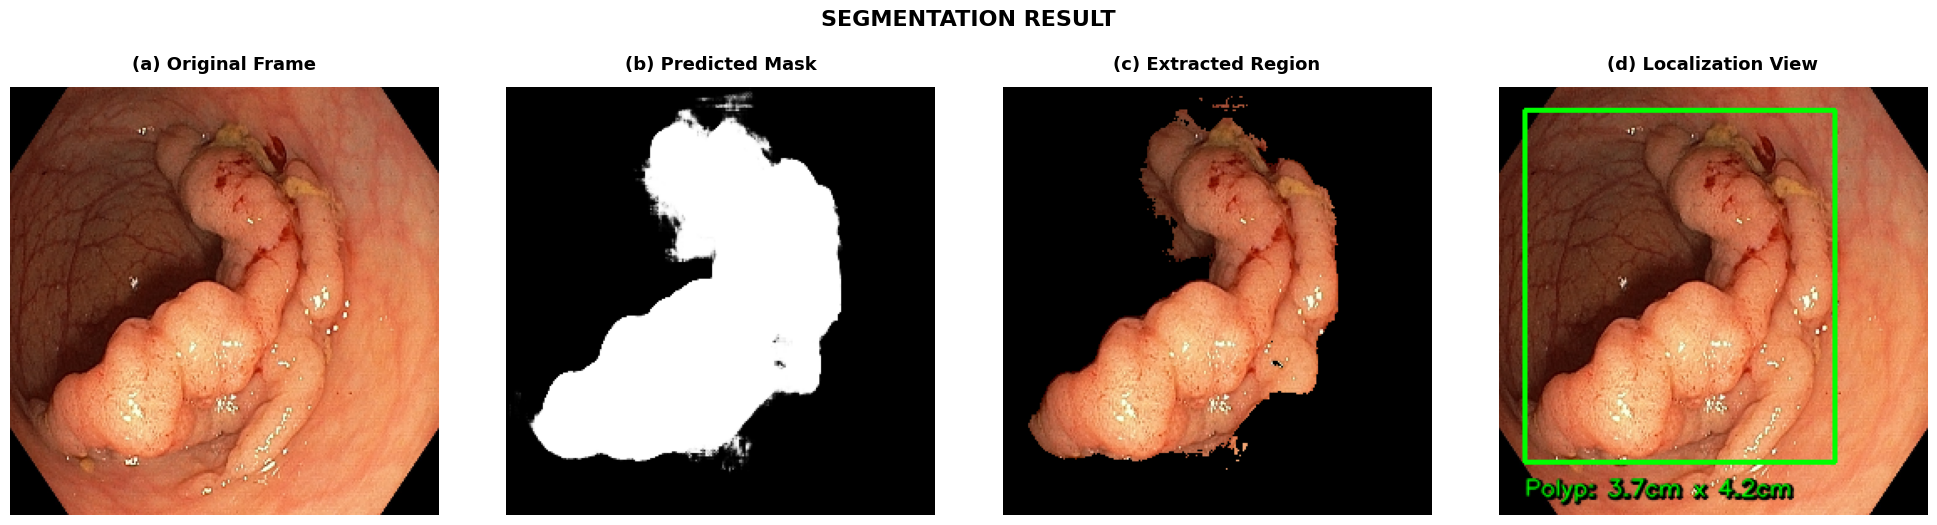

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg3_genetic.png
   • Fidelity-Focused     fitness=0.880  program=close5(fill_holes(open3(median5(open3(gaussian5(mask))))))
   • Smoothness-Focused   fitness=0.623  program=median5(open5(median3(open5(mask))))
   • Balanced             fitness=0.725  program=dilate3(open5(erode3(median5(median5(mask)))))
   • Compact-Region       fitness=0.584  program=gaussian3(open5(median5(median5(median5(open5(mask))))))


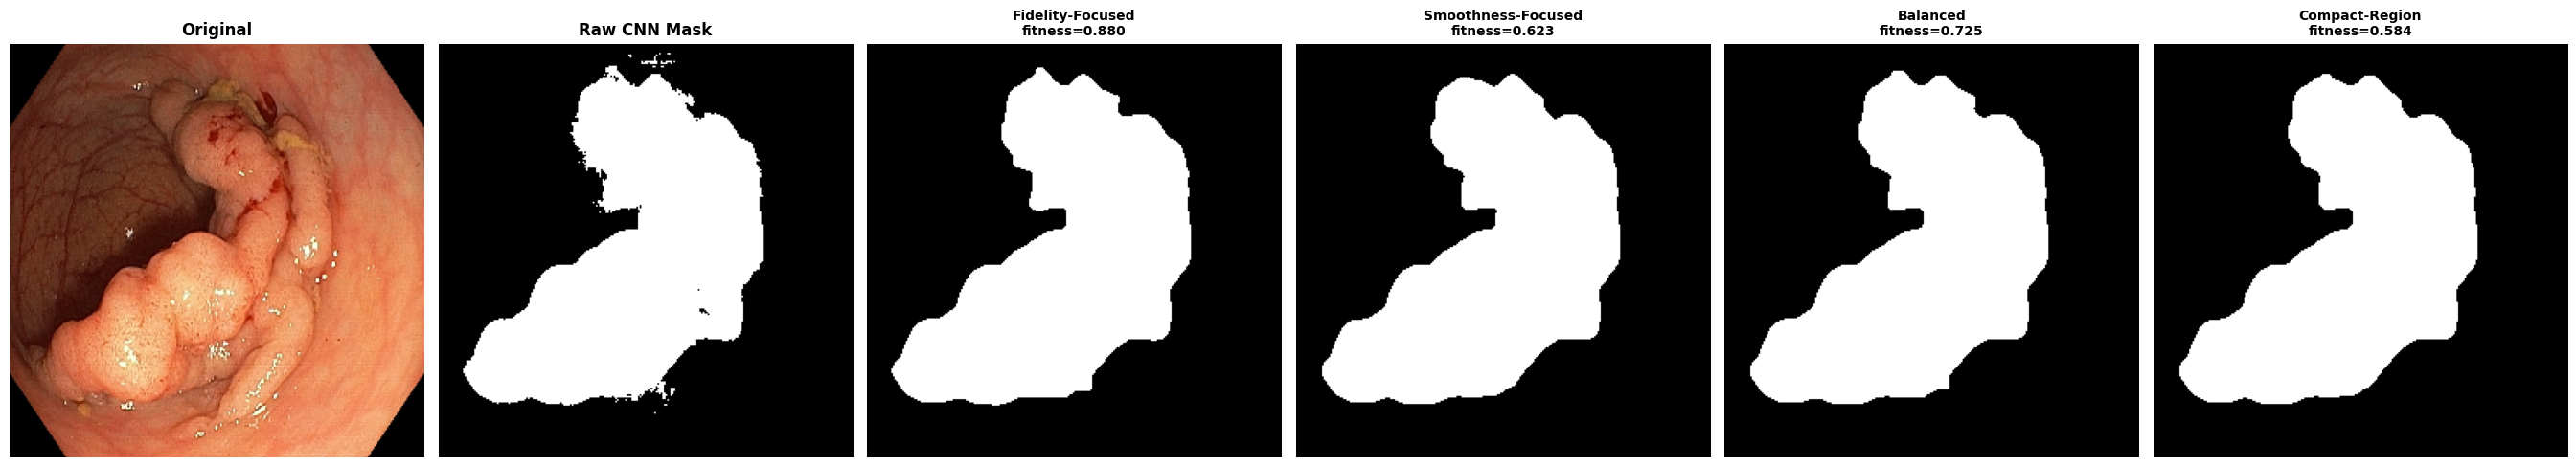


🎬 Processing Specimen 4...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg4.png


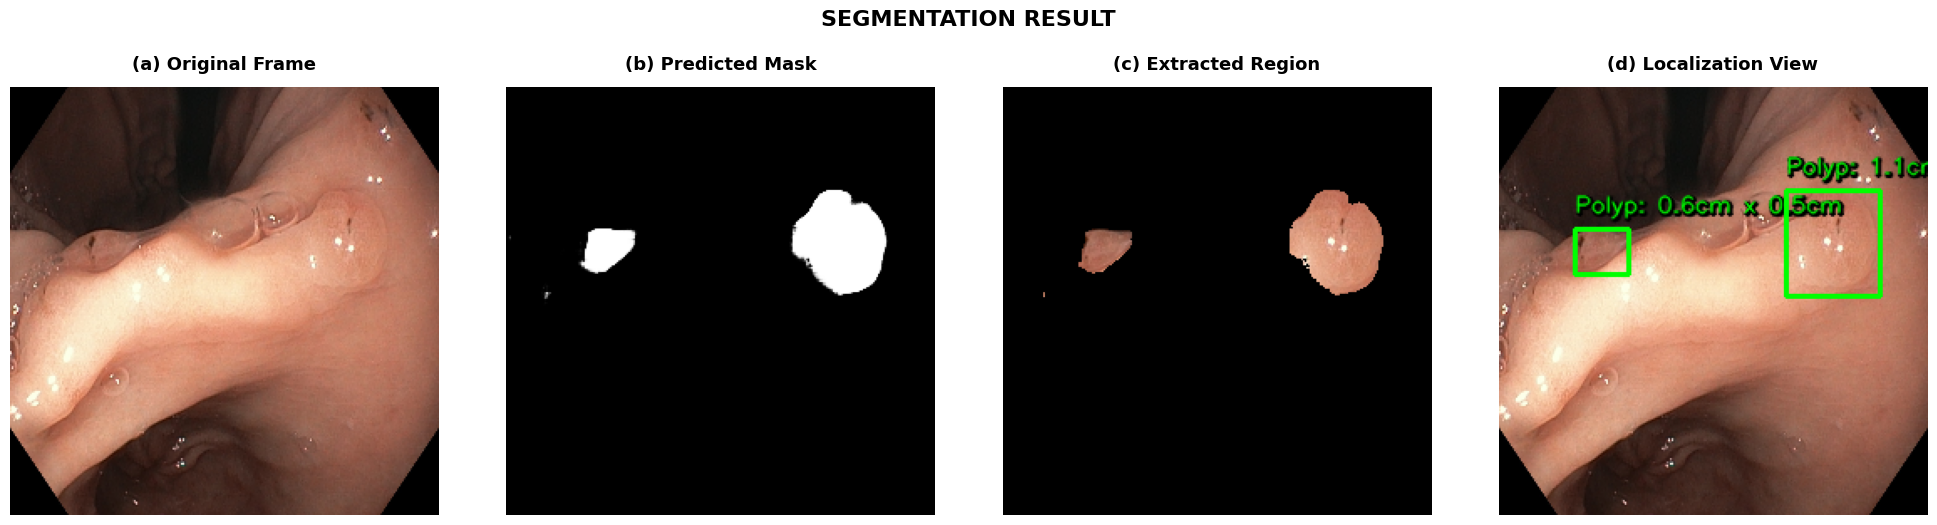

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg4_genetic.png
   • Fidelity-Focused     fitness=0.927  program=gaussian5(median3(median3(close5(close5(mask)))))
   • Smoothness-Focused   fitness=0.831  program=median5(open3(gaussian3(median5(median3(mask)))))
   • Balanced             fitness=0.868  program=close5(median5(median5(median5(close5(mask)))))
   • Compact-Region       fitness=0.642  program=median3(close3(keep_largest(mask)))


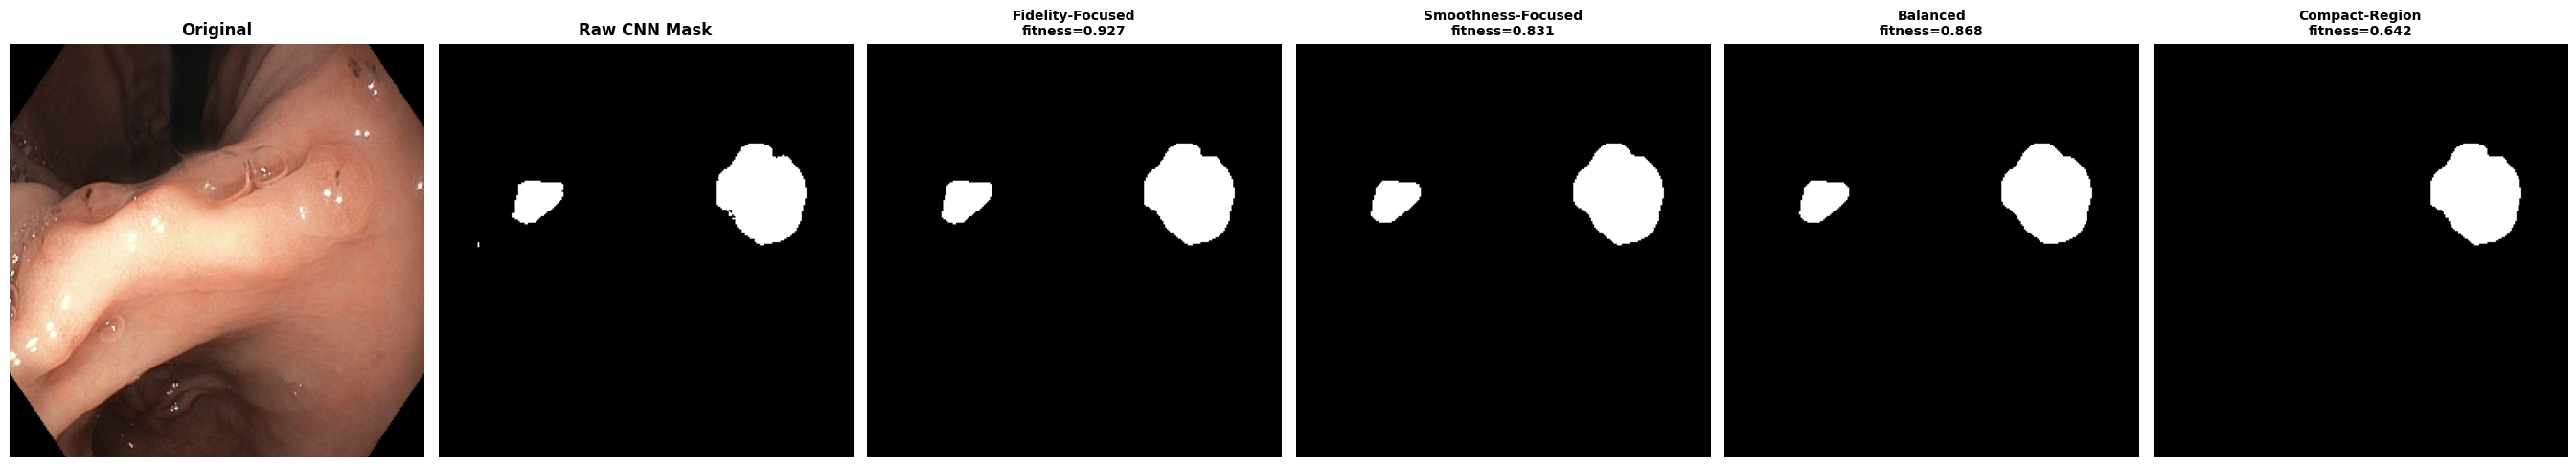


🎬 Processing Specimen 5...
🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: Neg5.png


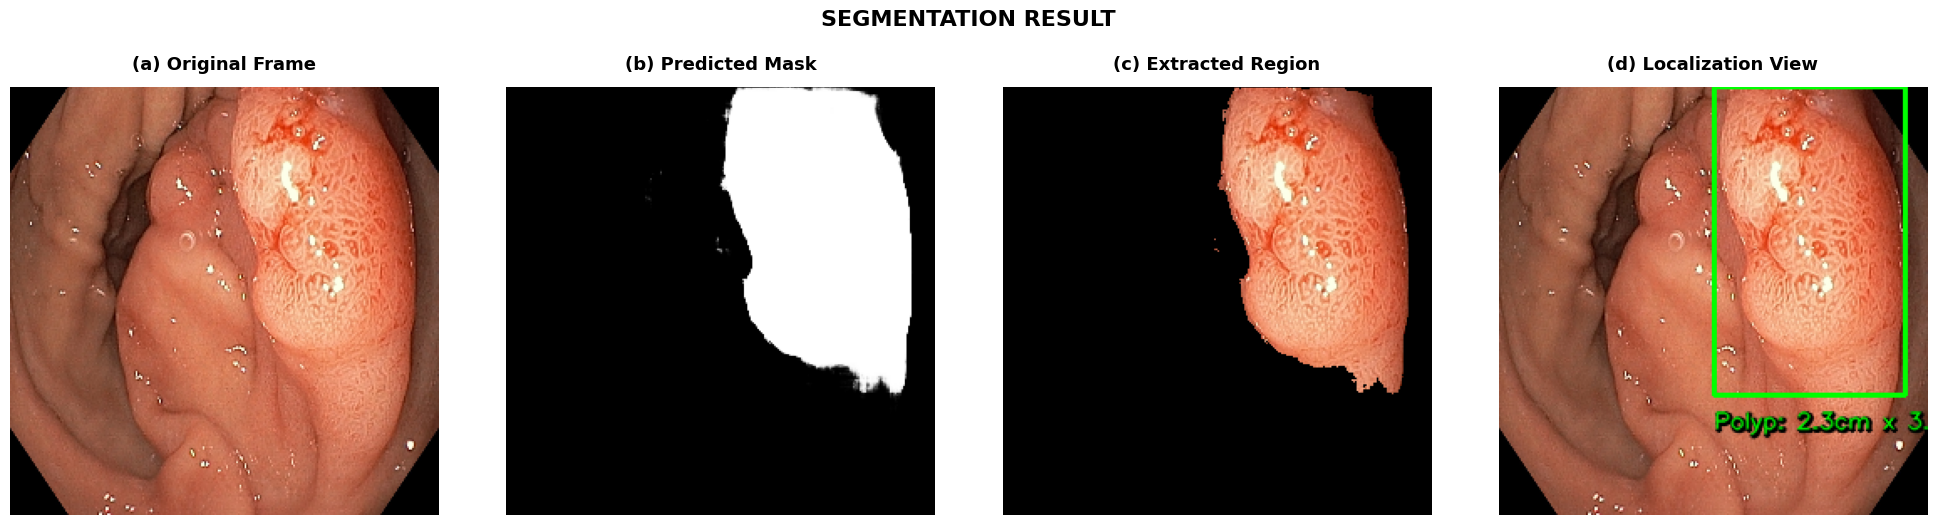

🧬 [GP SUCCESS] Genetic mask comparison saved to: Neg5_genetic.png
   • Fidelity-Focused     fitness=0.934  program=median3(median5(median5(median5(median5(open3(mask))))))
   • Smoothness-Focused   fitness=0.787  program=median5(open5(open3(mask)))
   • Balanced             fitness=0.846  program=open3(median5(median5(keep_largest(open5(mask)))))
   • Compact-Region       fitness=0.676  program=median3(open3(median5(open5(mask))))


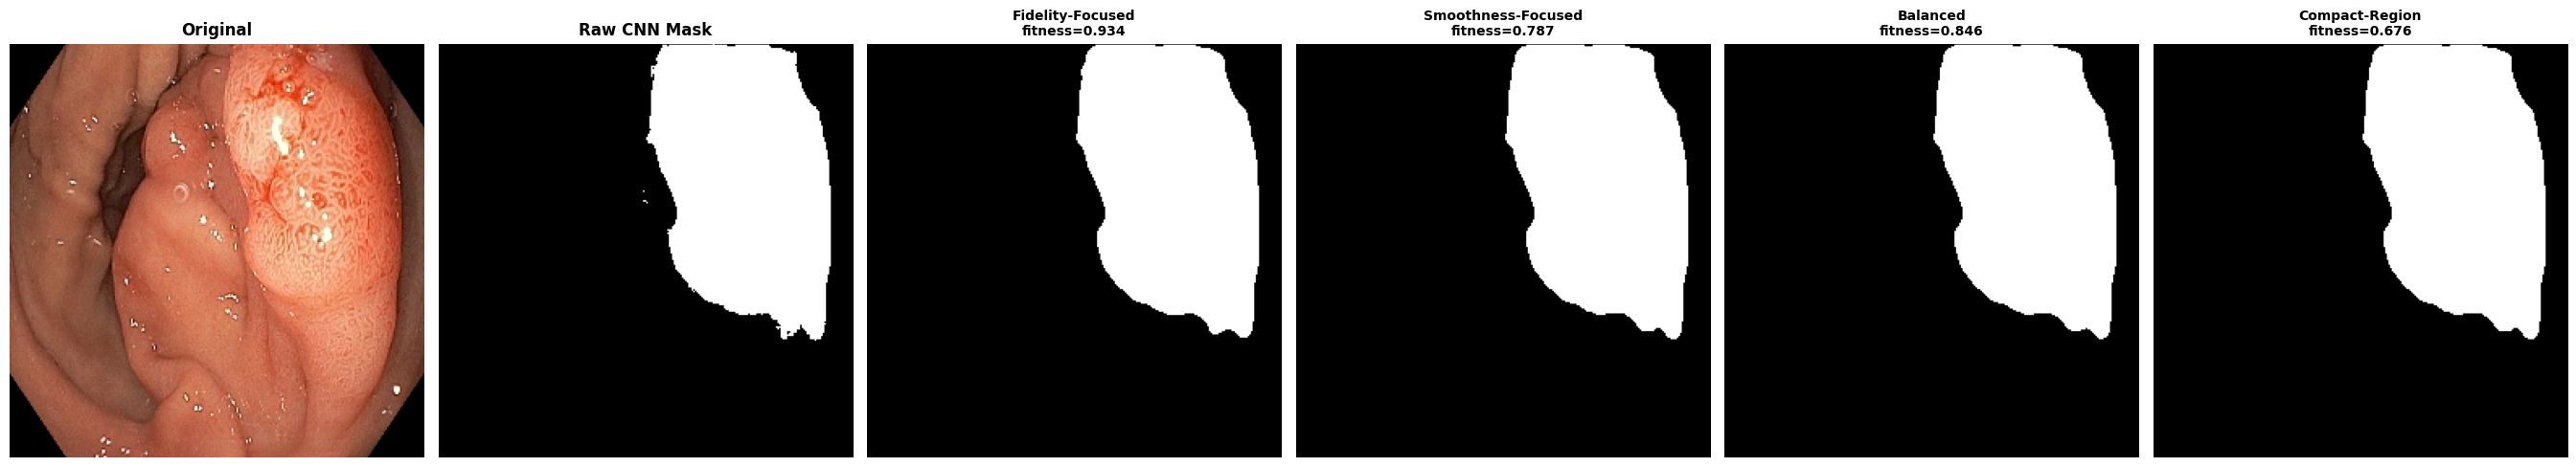

In [1]:
%matplotlib inline

import os
import cv2
import gc
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from deap import base, creator, tools, gp, algorithms

# ─────────────────────────────────────────────────────────────────────────────
# 🛠️ WSL / GPU & THREADING FIXES (কার্নেল ক্র্যাশ ও হ্যাং হওয়া বন্ধ করার জন্য)
# ─────────────────────────────────────────────────────────────────────────────
# ১. OpenCV থ্রেড ০ করা (WSL ও TensorFlow-এর ইন্টারনাল ডেডলক রোধ করতে)
cv2.setNumThreads(0)

# ২. TensorFlow GPU Memory Growth এনাবল করা (ভিও র‍্যাম ওভারফ্লো হওয়া আটকাতে)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✅ GPU Memory Growth Enabled")
    except RuntimeError as e:
        print(f"⚠️ GPU Growth Setup Error: {e}")

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ CONFIG
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

TEST_IMAGES = [
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0084.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/155OLCV1_100H0010.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/963OLCV1_100H0006.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/779OLCV1_100H0004.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/375OLCV1_100H0008.jpg"
]

# ─────────────────────────────────────────────────────────────────────────────
# 🧬 CUSTOM LAYER (self-contained লোডিং এর জন্য)
# ─────────────────────────────────────────────────────────────────────────────
@keras.saving.register_keras_serializable(package="Custom")
class KerasPCCLayer(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs
        mean = tf.reduce_mean(x, axis=-1, keepdims=True)
        std = tf.math.reduce_std(x, axis=-1, keepdims=True) + 1e-7
        x_norm = (x - mean) / std
        outer = tf.matmul(tf.expand_dims(x_norm, axis=2), tf.expand_dims(x_norm, axis=1))
        batch = tf.shape(x)[0]
        c = tf.shape(x)[-1]
        return tf.reshape(outer, [batch, c * c])

    def compute_output_shape(self, input_shape):
        c = input_shape[-1]
        return (input_shape[0], c * c if c is not None else None)

    def get_config(self):
        return super().get_config()

# ─────────────────────────────────────────────────────────────────────────────
# 🎨 LOCALIZATION HELPER (শুধু সেগমেন্টেশনের ওপর ভিত্তি করে, ক্লাসিফিকেশন ছাড়াই)
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pixel_to_cm_ratio = 50
    for cnt in contours:
        if cv2.contourArea(cnt) < 10:
            continue
        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"

        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        cv2.putText(res_img, size_text, (x + 1, text_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)
        cv2.putText(res_img, size_text, (x, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

    return res_img

# ─────────────────────────────────────────────────────────────────────────────
# 🧬 GENETIC PROGRAMMING MODULE — MULTI-MASK BOUNDARY REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
GP_POP_SIZE = 24
GP_NGEN = 8

GP_PROFILES = [
    {"name": "Fidelity-Focused",   "w_iou": 0.80, "w_circ": 0.20, "comp_penalty": 0.03},
    {"name": "Smoothness-Focused", "w_iou": 0.30, "w_circ": 0.70, "comp_penalty": 0.05},
    {"name": "Balanced",           "w_iou": 0.50, "w_circ": 0.50, "comp_penalty": 0.05},
    {"name": "Compact-Region",     "w_iou": 0.40, "w_circ": 0.40, "comp_penalty": 0.15},
]

def _morph(mask, op, k):
    kernel = np.ones((k, k), np.uint8)
    return cv2.morphologyEx(mask, op, kernel)

def op_erode3(mask):  return cv2.erode(mask, np.ones((3, 3), np.uint8))
def op_erode5(mask):  return cv2.erode(mask, np.ones((5, 5), np.uint8))
def op_dilate3(mask): return cv2.dilate(mask, np.ones((3, 3), np.uint8))
def op_dilate5(mask): return cv2.dilate(mask, np.ones((5, 5), np.uint8))
def op_open3(mask):   return _morph(mask, cv2.MORPH_OPEN, 3)
def op_open5(mask):   return _morph(mask, cv2.MORPH_OPEN, 5)
def op_close3(mask):  return _morph(mask, cv2.MORPH_CLOSE, 3)
def op_close5(mask):  return _morph(mask, cv2.MORPH_CLOSE, 5)
def op_median3(mask): return cv2.medianBlur(mask, 3)
def op_median5(mask): return cv2.medianBlur(mask, 5)

def op_gaussian3(mask):
    blurred = cv2.GaussianBlur(mask, (3, 3), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_gaussian5(mask):
    blurred = cv2.GaussianBlur(mask, (5, 5), 0)
    _, out = cv2.threshold(blurred, 127, 255, cv2.THRESH_BINARY)
    return out

def op_keep_largest(mask):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return mask
    out = np.zeros_like(mask)
    largest = max(contours, key=cv2.contourArea)
    cv2.drawContours(out, [largest], -1, 255, thickness=cv2.FILLED)
    return out

def op_fill_holes(mask):
    h, w = mask.shape
    flood = mask.copy()
    ff_mask = np.zeros((h + 2, w + 2), np.uint8)
    cv2.floodFill(flood, ff_mask, (0, 0), 255)
    flood_inv = cv2.bitwise_not(flood)
    return mask | flood_inv

# ── Single-type (untyped) GP primitive set ──
pset = gp.PrimitiveSet("MASK_GP", 1)
pset.renameArguments(ARG0="mask")

_PRIMITIVES = [
    (op_erode3, "erode3"), (op_erode5, "erode5"),
    (op_dilate3, "dilate3"), (op_dilate5, "dilate5"),
    (op_open3, "open3"), (op_open5, "open5"),
    (op_close3, "close3"), (op_close5, "close5"),
    (op_median3, "median3"), (op_median5, "median5"),
    (op_gaussian3, "gaussian3"), (op_gaussian5, "gaussian5"),
    (op_keep_largest, "keep_largest"), (op_fill_holes, "fill_holes"),
]
for _func, _name in _PRIMITIVES:
    pset.addPrimitive(_func, 1, name=_name)

if not hasattr(creator, "GPFitnessMax"):
    creator.create("GPFitnessMax", base.Fitness, weights=(1.0,))
if not hasattr(creator, "GPIndividual"):
    creator.create("GPIndividual", gp.PrimitiveTree, fitness=creator.GPFitnessMax)

def eval_mask_program(individual, raw_mask_uint8, profile, compiler):
    func = compiler(expr=individual)
    try:
        candidate = func(raw_mask_uint8.copy())
    except Exception:
        return (-1.0,)

    if candidate is None or not isinstance(candidate, np.ndarray):
        return (-1.0,)
    candidate = (candidate > 127).astype(np.uint8) * 255
    if candidate.sum() == 0:
        return (-1.0,)

    inter = np.logical_and(candidate > 0, raw_mask_uint8 > 0).sum()
    union = np.logical_or(candidate > 0, raw_mask_uint8 > 0).sum()
    iou = inter / (union + 1e-7)

    contours, _ = cv2.findContours(candidate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return (-1.0,)
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    perimeter = cv2.arcLength(largest, True)
    if area <= 0 or perimeter <= 0:
        return (-1.0,)
    circularity = min((4 * np.pi * area) / (perimeter ** 2), 1.0)

    component_penalty = max(0, len(contours) - 1) * profile["comp_penalty"]

    score = (profile["w_iou"] * iou) + (profile["w_circ"] * circularity) - component_penalty
    return (score,)

def build_gp_toolbox(raw_mask_uint8, profile):
    toolbox = base.Toolbox()
    toolbox.register("expr", gp.genGrow, pset=pset, min_=1, max_=4)
    toolbox.register("individual", tools.initIterate, creator.GPIndividual, toolbox.expr)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("compile", gp.compile, pset=pset)
    toolbox.register("evaluate", eval_mask_program, raw_mask_uint8=raw_mask_uint8,
                     profile=profile, compiler=toolbox.compile)
    toolbox.register("mate", gp.cxOnePoint)
    toolbox.register("expr_mut", gp.genGrow, min_=0, max_=2)
    toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.decorate("mate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    toolbox.decorate("mutate", gp.staticLimit(key=lambda ind: ind.height, max_value=6))
    return toolbox

def run_gp_evolution(raw_mask_uint8, profile, pop_size=GP_POP_SIZE, ngen=GP_NGEN, seed=None):
    if seed is not None:
        random.seed(seed)

    toolbox = build_gp_toolbox(raw_mask_uint8, profile)
    pop = toolbox.population(n=pop_size)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.6, mutpb=0.3, ngen=ngen,
                        halloffame=hof, verbose=False)

    best = hof[0]
    func = toolbox.compile(expr=best)
    refined = func(raw_mask_uint8.copy())
    refined = (refined > 127).astype(np.uint8) * 255
    return refined, str(best), best.fitness.values[0]

def generate_genetic_masks(raw_mask_uint8, pop_size=GP_POP_SIZE, ngen=GP_NGEN):
    results = []
    for i, profile in enumerate(GP_PROFILES):
        mask, program_str, score = run_gp_evolution(
            raw_mask_uint8, profile, pop_size=pop_size, ngen=ngen, seed=100 + i
        )
        results.append({
            "name": profile["name"],
            "mask": mask,
            "program": program_str,
            "fitness": score,
        })
    return results

def to_binary_uint8(prob_mask, thresh=0.5):
    m = prob_mask
    if m.ndim == 3:
        m = m[..., 0]
    return (m > thresh).astype(np.uint8) * 255

def plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, output_filename):
    n = len(genetic_results) + 2  
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img_res)
    axes[0].set_title("Original", fontweight="bold")
    axes[0].axis("off")

    axes[1].imshow(raw_mask_uint8, cmap="gray")
    axes[1].set_title("Raw CNN Mask", fontweight="bold")
    axes[1].axis("off")

    for i, res in enumerate(genetic_results):
        ax = axes[2 + i]
        ax.imshow(res["mask"], cmap="gray")
        ax.set_title(f"{res['name']}\nfitness={res['fitness']:.3f}", fontsize=10, fontweight="bold")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches="tight")
    print(f"🧬 [GP SUCCESS] Genetic mask comparison saved to: {output_filename}")
    for res in genetic_results:
        print(f"   • {res['name']:<20} fitness={res['fitness']:.3f}  program={res['program']}")
    plt.show()
    plt.close(fig)  # 👈 [FIX] মেমোরি ফ্রী করে কার্নেল সুস্থ রাখার জন্য

# ─────────────────────────────────────────────────────────────────────────────
# 🔮 SEGMENTATION-ONLY INFERENCE + GP MULTI-MASK REFINEMENT
# ─────────────────────────────────────────────────────────────────────────────
def preprocess(image_path):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, inp

def test_and_display(seg_model, image_path, output_filename='result.png'):
    img_res, inp = preprocess(image_path)

    pred = seg_model.predict(inp, verbose=0)
    pred_mask_spatial = pred[0]  

    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)

    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    plt.suptitle("SEGMENTATION RESULT", fontsize=16, fontweight='bold', y=1.04)
    plt.tight_layout()
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [SEG SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()
    plt.close(fig)  # 👈 [FIX] Matplotlib মেমোরি লিক ফিক্স

    # ── 🧬 GP MULTI-MASK REFINEMENT (৪টা মাস্ক পাশাপাশি) ──
    raw_mask_uint8 = to_binary_uint8(pred_mask_spatial)
    genetic_results = generate_genetic_masks(raw_mask_uint8)
    gp_output_filename = output_filename.replace('.png', '_genetic.png')
    plot_genetic_masks(img_res, raw_mask_uint8, genetic_results, gp_output_filename)

    gc.collect()

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────
if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph...")
    full_model = tf.keras.models.load_model(
        MODEL_PATH, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # শুধু সেগমেন্টেশন আউটপুট পর্যন্ত সাব-মডেল
    seg_model = tf.keras.Model(
        inputs=full_model.inputs,
        outputs=full_model.get_layer(name="seg_output").output,
        name="segmentation_only_model",
    )
    print("✅ Segmentation-only sub-model ready.\n")

    output_names = ['thesis_positive_result.png', 'thesis_negative_result.png',
                    'Neg3.png', 'Neg4.png', 'Neg5.png']

    for i, path in enumerate(TEST_IMAGES):
        print(f"🎬 Processing Specimen {i + 1}...")
        test_and_display(seg_model, path, output_names[i])
        print()

In [ ]:
%matplotlib inline

import os
import cv2
import gc
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from deap import base, creator, tools, gp, algorithms
from sklearn.decomposition import PCA

# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ CONFIGURATIONS & TEST IMAGES
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"

TEST_IMAGES = [
        "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0084.jpg",
"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/155OLCV1_100H0010.jpg",
"/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/963OLCV1_100H0006.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/779OLCV1_100H0004.jpg",
 "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/375OLCV1_100H0008.jpg"
]

# ─────────────────────────────────────────────────────────────────────────────
# 🧬 CUSTOM LAYER HANDLING
# ─────────────────────────────────────────────────────────────────────────────
@keras.saving.register_keras_serializable(package="Custom")
class KerasPCCLayer(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs
        mean = tf.reduce_mean(x, axis=-1, keepdims=True)
        std = tf.math.reduce_std(x, axis=-1, keepdims=True) + 1e-7
        x_norm = (x - mean) / std
        outer = tf.matmul(tf.expand_dims(x_norm, axis=2), tf.expand_dims(x_norm, axis=1))
        batch = tf.shape(x)[0]
        c = tf.shape(x)[-1]
        return tf.reshape(outer, [batch, c * c])

    def compute_output_shape(self, input_shape):
        c = input_shape[-1]
        return (input_shape[0], c * c if c is not None else None)

    def get_config(self):
        return super().get_config()

# ─────────────────────────────────────────────────────────────────────────────
# 🧮 GENETIC PROGRAMMING (GP) FEATURE FUSION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
GP_POP_SIZE = 30
GP_NGEN = 8

GP_PROFILES = [
    {"name": "Fidelity-Focused",   "w_iou": 0.80, "w_circ": 0.20, "comp_penalty": 0.03},
    {"name": "Smoothness-Focused", "w_iou": 0.30, "w_circ": 0.70, "comp_penalty": 0.05},
    {"name": "Balanced",           "w_iou": 0.50, "w_circ": 0.50, "comp_penalty": 0.05},
    {"name": "Compact-Region",     "w_iou": 0.40, "w_circ": 0.40, "comp_penalty": 0.15},
]

# Safe mathematical primitives for feature maps
def safe_div(left, right):
    return np.divide(left, right, out=np.zeros_like(left), where=right!=0)

def gp_sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -10, 10)))

# GP Tree takes 4 Principal Feature Maps as input
pset = gp.PrimitiveSet("FEATURE_GP", 4)
pset.renameArguments(ARG0="F1", ARG1="F2", ARG2="F3", ARG3="F4")

pset.addPrimitive(np.add, 2, name="add")
pset.addPrimitive(np.subtract, 2, name="sub")
pset.addPrimitive(np.multiply, 2, name="mul")
pset.addPrimitive(safe_div, 2, name="div")
pset.addPrimitive(np.maximum, 2, name="max")
pset.addPrimitive(gp_sigmoid, 1, name="sigmoid")

if not hasattr(creator, "FeatureFitness"):
    creator.create("FeatureFitness", base.Fitness, weights=(1.0,))
if not hasattr(creator, "FeatureIndividual"):
    creator.create("FeatureIndividual", gp.PrimitiveTree, fitness=creator.FeatureFitness)

def eval_feature_fusion(individual, features_list, reference_mask_uint8, profile, compiler):
    func = compiler(expr=individual)
    try:
        # Pass the 4 feature maps into the GP mathematical equation
        raw_output = func(*features_list)
        if not isinstance(raw_output, np.ndarray):
            raw_output = np.full(reference_mask_uint8.shape, raw_output)
    except Exception:
        return (-1.0,)

    # Convert GP output to a binary mask using threshold 0.5
    candidate = (raw_output > 0.5).astype(np.uint8) * 255
    if candidate.sum() == 0:
        return (-1.0,)

    # Calculate metrics against the CNN's raw prediction (Pseudo-Ground Truth)
    inter = np.logical_and(candidate > 0, reference_mask_uint8 > 0).sum()
    union = np.logical_or(candidate > 0, reference_mask_uint8 > 0).sum()
    iou = inter / (union + 1e-7)

    contours, _ = cv2.findContours(candidate, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return (-1.0,)
    
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    perimeter = cv2.arcLength(largest, True)
    if area <= 0 or perimeter <= 0:
        return (-1.0,)
    circularity = min((4 * np.pi * area) / (perimeter ** 2), 1.0)
    
    component_penalty = max(0, len(contours) - 1) * profile["comp_penalty"]
    score = (profile["w_iou"] * iou) + (profile["w_circ"] * circularity) - component_penalty
    
    return (score,)

def run_gp_feature_evolution(features_list, reference_mask_uint8, profile, seed=None):
    if seed is not None:
        random.seed(seed)

    toolbox = base.Toolbox()
    toolbox.register("expr", gp.genHalfAndHalf, pset=pset, min_=1, max_=3)
    toolbox.register("individual", tools.initIterate, creator.FeatureIndividual, toolbox.expr)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)
    toolbox.register("compile", gp.compile, pset=pset)
    
    toolbox.register("evaluate", eval_feature_fusion, features_list=features_list, 
                     reference_mask_uint8=reference_mask_uint8, profile=profile, compiler=toolbox.compile)
    toolbox.register("mate", gp.cxOnePoint)
    toolbox.register("expr_mut", gp.genGrow, min_=0, max_=2)
    toolbox.register("mutate", gp.mutUniform, expr=toolbox.expr_mut, pset=pset)
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.decorate("mate", gp.staticLimit(key=lambda ind: ind.height, max_value=5))
    toolbox.decorate("mutate", gp.staticLimit(key=lambda ind: ind.height, max_value=5))

    pop = toolbox.population(n=GP_POP_SIZE)
    hof = tools.HallOfFame(1)
    algorithms.eaSimple(pop, toolbox, cxpb=0.6, mutpb=0.3, ngen=GP_NGEN, halloffame=hof, verbose=False)

    best_expr = hof[0]
    func = toolbox.compile(expr=best_expr)
    final_raw_output = func(*features_list)
    if not isinstance(final_raw_output, np.ndarray):
        final_raw_output = np.full(reference_mask_uint8.shape, final_raw_output)
        
    refined_mask = (final_raw_output > 0.5).astype(np.uint8) * 255
    return refined_mask, str(best_expr), best_expr.fitness.values[0]

# ─────────────────────────────────────────────────────────────────────────────
# 🚀 MAIN PIPELINE: CNN FEATURE EXTRACTION + PCA + GP
# ─────────────────────────────────────────────────────────────────────────────
def preprocess(image_path):
    img = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    cl = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:,:,0])
    limg = cv2.merge((cl, lab[:,:,1], lab[:,:,2]))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, cv2.medianBlur(enhanced_img, 3), -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, inp

if __name__ == '__main__':
    print("⏳ Loading Keras Architecture Graph...")
    full_model = tf.keras.models.load_model(MODEL_PATH, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False)

    # TARGET LAYER: global_average_pooling2d_8
    # We extract the INPUT to this layer to get Spatial Features (H, W, Channels) instead of a 1D vector.
    target_gap_layer = full_model.get_layer(name="dense_16")
    spatial_features_tensor = target_gap_layer.input 
    
    # We also extract the seg_output to act as our Pseudo-Ground Truth for the Fitness Function
    seg_output_tensor = full_model.get_layer(name="seg_output").output

    feature_extractor = tf.keras.Model(
        inputs=full_model.inputs,
        outputs=[spatial_features_tensor, seg_output_tensor],
        name="feature_to_mask_extractor"
    )
    print("✅ Feature-to-Mask extraction sub-model ready.\n")

    for i, path in enumerate(TEST_IMAGES):
        if not os.path.exists(path):
            continue
        print(f"🎬 Processing Specimen {i + 1}...")
        img_res, inp = preprocess(path)

        # Extract features and CNN predicted mask
        spatial_feats, cnn_mask_pred = feature_extractor.predict(inp, verbose=0)
        spatial_feats = spatial_feats[0] # Shape: (256, 256, C)
        cnn_mask_uint8 = (cnn_mask_pred[0, :, :, 0] > 0.5).astype(np.uint8) * 255

        # ── PCA Dimensionality Reduction ──
        # Reduce deep channels (e.g., 32 or 64) into 4 Principal Spatial Feature Maps to feed into GP
        h, w, c = spatial_feats.shape
        flat_feats = spatial_feats.reshape(h * w, c)
        pca = PCA(n_components=4)
        pca_reduced = pca.fit_transform(flat_feats)
        
        # Normalize and separate the 4 principal feature maps
        features_list = []
        for j in range(4):
            f_map = pca_reduced[:, j].reshape(h, w)
            f_map = cv2.normalize(f_map, None, 0, 1, cv2.NORM_MINMAX)
            features_list.append(f_map)

        # ── Generate GP Masks directly from Features ──
        genetic_results = []
        for j, profile in enumerate(GP_PROFILES):
            mask, formula, score = run_gp_feature_evolution(features_list, cnn_mask_uint8, profile, seed=42+j)
            genetic_results.append({"name": profile["name"], "mask": mask, "program": formula, "fitness": score})

        # ── Plotting ──
        n_plots = len(genetic_results) + 2
        fig, axes = plt.subplots(1, n_plots, figsize=(4.5 * n_plots, 5))

        axes[0].imshow(img_res)
        axes[0].set_title("Original Frame", fontweight="bold")
        axes[0].axis("off")

        axes[1].imshow(cnn_mask_uint8, cmap="gray")
        axes[1].set_title("Reference CNN Mask", fontweight="bold")
        axes[1].axis("off")

        for k, res in enumerate(genetic_results):
            axes[2 + k].imshow(res["mask"], cmap="gray")
            axes[2 + k].set_title(f"{res['name']}\nFitness: {res['fitness']:.3f}", fontsize=10, fontweight="bold")
            axes[2 + k].axis("off")

        plt.tight_layout()
        out_name = f"Feature_Evolved_Mask_{i+1}.png"
        plt.savefig(out_name, dpi=300, bbox_inches="tight")
        print(f"🧬 [SUCCESS] Image saved: {out_name}")
        for res in genetic_results:
            print(f"   • {res['name']:<20} Formula: {res['program']}")
        
        plt.show()
        plt.close(fig)
        gc.collect()

⏳ Loading Keras Architecture Graph...
✅ Feature-to-Mask extraction sub-model ready.

🎬 Processing Specimen 1...
